# NK cells: cytotoxic behavior, IFN-γ, adenosine and recruitment under RT (single cell + spatial check)

Follow-up to `01_macrophage_rt.ipynb`. There is no RT-only arm, so every question is about **what RT
improves on**, in both CAR backgrounds or specifically with PSCA (CAR × RT).

| part | question |
|---|---|
| 1 | Do NK cells express more IFN-γ in the abscopal tumor (Tu2)? Who supplies IFN-γ there, and how does that square with the myeloid ISG loss? |
| 2 | What is the NK cytotoxic / activation / inhibition phenotype, and what does RT change in it? |
| 3 | Is the CD73 / adenosine axis still present in the abscopal tumor? Do NK cells carry the adenosine receptors? |
| 4 | What is the recruitment environment for NK cells (abundance, homing receptors, ligands, activating vs suppressive cues), and does RT help? |
| 5 | Check against the tumor-wide immediate-early (stress) program; scorecard of hits vs chance |

### Data and statistics
* **Single cell:** pseudobulks from `mhcCytotoxExhaustion/00`, plus per-cell counts for NK / NKT / T cells
  read from `annotation_v4.h5ad` (`layers/counts`).
  - NK numbers are small: 5–107 per tumor, and 5–55 in Tu2.
  - NK readouts use tumors with **≥ 5 NK cells**, the threshold `mhcCytotoxFigures` used, and are shown
    with their cell counts.
* **Spatial cross-check:**
  - **Source:** segmentation-level counts (19,059 genes, 2.09 M cells, c2l labels), 31 tumors.
    `RTCyPSCA_1_2` and `_1_5` are two sections of one tumor and are merged.
  - **NK-labeled cells:** tens to thousands per tumor; NK expression readouts need ≥ 30 NK-labeled cells.
  - **Spillover floor:** spatial detection can come from neighboring cells, so every NK readout is
    compared with the same gene's detection in tumor cells of the same section.
* **Contrasts:**
  - **RT in PSCA / RT in TAG72** = RT − no RT within one CAR at one site.
  - **Pooled** = the mean of the two.
  - **CAR × RT** = (RT in PSCA) − (RT in TAG72).
  - **PSCA effect** = PSCA − TAG72 within an RT stratum.
* **p-values:**
  - Exact relabelling; within one CAR the floor is 0.10 at 3 v 3, so per-CAR rows also give a Welch t p.
  - Per-cell binomial GLMM (random intercept per tumor) for key markers; it uses every cell but overstates
    certainty with 5–6 tumors.
  - pydeseq2 per site (`~ car + rt + car:rt`) for NK pseudobulks.
* **Orientation for the scorecard** (▲ favors NK killing, ▼ suppresses NK, · context) is the textbook
  role, a reading aid only.

## 0. Config, style, engine

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools, logging, time, re, json
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from statsmodels.stats.multitest import multipletests
logging.disable(logging.WARNING)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 400)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
SRC = PROJ/"results/mhc_cytotox"; RA = PROJ/"results/rt_advantage"
SC_REF = (PROJ/"data/sc-reference/annotation_v4.h5ad" if PROJ is _LOC
          else PROJ/"data/zarr/fullDataset/annotating_references/annotation_v4.h5ad")
ZARR = (PROJ/"data/zarrFiles/1_C2l_annotations_400" if PROJ is _LOC
        else PROJ/"data/zarr/fullDataset/processing_Zarr/1_C2l_annotated_CC")
GMT_DIR = PROJ/"data/references/pathways"
OUT = RA/"specific_cell_type/nk"; OUT.mkdir(parents=True, exist_ok=True)
for f_ in [SRC/"pseudobulk_counts.parquet", SRC/"pseudobulk_meta.csv", SRC/"programs.json", SC_REF,
           RA/"design_spatial.csv", RA/"census_spatial_per_tissue.csv", RA/"infiltration_metrics_per_tissue.csv"]:
    assert Path(f_).exists(), f"missing {f_}"
MIN_NK, MIN_PB, SEED, N_PERM, MIN_SP_NK = 5, 10, 0, 1000, 30

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"
S_GOOD, S_WARN, S_CRIT = "#0ca30c", "#fab219", "#d03b3b"
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
                                                "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba", "#382887", "#231859"])
mpl.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 8.6,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300, "text.color": INK})

ARMS4 = ["CyPSCA", "RTCyPSCA", "CyT72", "RTCyT72"]
ARM_LAB = {"CyPSCA": "PSCA\nno RT", "RTCyPSCA": "PSCA\n+ RT", "CyT72": "TAG72\nno RT", "RTCyT72": "TAG72\n+ RT", "NoTx": "Untreated"}
CAR_OF = {"CyPSCA": "PSCA", "RTCyPSCA": "PSCA", "CyT72": "TAG72", "RTCyT72": "TAG72", "NoTx": "none"}
RT_OF = {"CyPSCA": False, "RTCyPSCA": True, "CyT72": False, "RTCyT72": True, "NoTx": False}
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}


def norm_arm(a): return str(a).replace("TAG72", "T72")


def fmt_p(p):
    if p is None or not np.isfinite(p): return "n/a"
    return "<0.001" if p < 0.001 else (f"{p:.3f}" if p < 0.1 else f"{p:.2f}")


def _cell(v, meta, A, B, site):
    idx = [i for i in meta.index[meta.arm.isin([A, B]) & (meta.site == site)] if np.isfinite(v.get(i, np.nan))]
    a = v[[i for i in idx if meta.loc[i, "arm"] == A]]; b = v[[i for i in idx if meta.loc[i, "arm"] == B]]
    if len(a) < 2 or len(b) < 2: return None
    x = np.r_[a.values, b.values]; k = len(a)
    null = [a.mean() - b.mean()]
    for c in itertools.combinations(range(len(x)), k):
        if c == tuple(range(k)): continue
        m = np.isin(np.arange(len(x)), c); null.append(x[m].mean() - x[~m].mean())
    ss = ((a - a.mean()) ** 2).sum() + ((b - b.mean()) ** 2).sum()
    return dict(d=a.mean() - b.mean(), null=np.array(null), ss=ss, df=len(a) + len(b) - 2,
                inv=1 / len(a) + 1 / len(b), nA=len(a), nB=len(b), a=a.values, b=b.values)


def _combine(nulls, how="mean", cap=60000, seed=SEED):
    g_ = np.random.default_rng(seed); out = nulls[0]
    for k, nb in enumerate(nulls[1:], start=2):
        out = ((out[:, None] * (k - 1) + nb[None, :]) / k).ravel() if how == "mean" else (out[:, None] - nb[None, :]).ravel()
        if len(out) > cap: out = np.r_[out[:1], g_.choice(out[1:], cap, replace=False)]
    return out


def _p(null): return float((np.abs(null) >= abs(null[0]) - 1e-12).mean())


def stratum(v, meta, cells):
    cs = [c for c in (_cell(v, meta, *cell) for cell in cells) if c is not None]
    if not cs: return None
    K = len(cs); df = sum(c["df"] for c in cs); s2 = sum(c["ss"] for c in cs) / max(df, 1)
    welch = stats.ttest_ind(cs[0]["a"], cs[0]["b"], equal_var=False).pvalue if K == 1 else np.nan
    return dict(d=np.mean([c["d"] for c in cs]), se=np.sqrt(s2 * sum(c["inv"] for c in cs)) / K, df=df,
                null=_combine([c["null"] for c in cs]), n=" + ".join(f"{c['nA']}v{c['nB']}" for c in cs), welch=welch)


EFFECTS = {
    "RT Tu1":   [("PSCA", [("RTCyPSCA", "CyPSCA", 1)]), ("TAG72", [("RTCyT72", "CyT72", 1)])],
    "RT Tu2":   [("PSCA", [("RTCyPSCA", "CyPSCA", 2)]), ("TAG72", [("RTCyT72", "CyT72", 2)])],
    "PSCA Tu1": [("no RT", [("CyPSCA", "CyT72", 1)]), ("RT", [("RTCyPSCA", "RTCyT72", 1)])],
    "PSCA Tu2": [("no RT", [("CyPSCA", "CyT72", 2)]), ("RT", [("RTCyPSCA", "RTCyT72", 2)])],
}


def effect(v, meta, eff, scale=1.0):
    out = {}
    st = [(lab, stratum(v, meta, cells)) for lab, cells in EFFECTS[eff]]
    for lab, s in st:
        if s is None: continue
        h = stats.t.ppf(0.975, s["df"]) * s["se"]
        out[lab] = dict(est=s["d"] * scale, lo=(s["d"] - h) * scale, hi=(s["d"] + h) * scale,
                        p=_p(s["null"]), welch=s["welch"], n=s["n"])
    if all(s is not None for _, s in st):
        (l1, s1), (l2, s2) = st
        df = s1["df"] + s2["df"]; m = (s1["d"] + s2["d"]) / 2
        h = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2) / 2
        out["pooled"] = dict(est=m * scale, lo=(m - h) * scale, hi=(m + h) * scale,
                             p=_p(_combine([s1["null"], s2["null"]], "mean")), welch=np.nan, n="")
        hi_, lo_ = (s2, s1) if eff.startswith("PSCA") else (s1, s2)
        it = hi_["d"] - lo_["d"]; hh = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2)
        out["CARxRT"] = dict(est=it * scale, lo=(it - hh) * scale, hi=(it + hh) * scale,
                             p=_p(_combine([hi_["null"], lo_["null"]], "diff")), welch=np.nan, n="")
    return out


def effect_rows(v, meta, scale=1.0, effects=tuple(EFFECTS), **keys):
    rows = []
    for eff in effects:
        for part, d in effect(v, meta, eff, scale).items():
            rows.append({**keys, "effect": eff, "part": part, **d})
    return rows


def best_p(r):
    return r["welch"] if r["part"] in ("PSCA", "TAG72", "no RT", "RT") and np.isfinite(r.get("welch", np.nan)) else r["p"]


def sample_meta(samples):
    s = pd.Series(samples, index=samples)
    p = s.str.extract(r"^(?P<arm>.+)_Tu(?P<site>\d)_(?P<rep>\d+)$")
    m = pd.DataFrame({"arm": p.arm.map(norm_arm).values, "site": p.site.astype(int).values,
                      "mouse": (p.arm.map(norm_arm) + "_m" + p.rep).values}, index=samples)
    return m

## 1. Data — pseudobulks, per-cell NK / T counts (cached), whole-tumor pseudobulk

In [2]:
PB = pd.read_parquet(SRC/"pseudobulk_counts.parquet")
PBM = pd.read_csv(SRC/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
PBM["arm"] = PBM.arm.map(norm_arm)
L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)
PROGRAMS = json.load(open(SRC/"programs.json"))["programs"]

IEG_GENES = [g for g in ["Fos", "Fosb", "Jun", "Junb", "Jund", "Egr1", "Egr2", "Egr3", "Atf3", "Ier2", "Ier3", "Ier5", "Dusp1",
                         "Hspa1a", "Hspa1b", "Hspa8", "Hsp90aa1", "Hspb1", "Nr4a1", "Nr4a2", "Zfp36", "Klf2", "Klf4", "Klf6",
                         "Socs3", "Nfkbia", "Ppp1r15a", "Btg2", "Cebpd", "Gadd45b", "Ccn1", "Cyr61", "Rhob"] if g in PB.columns]
CELL_GENES = ["Ifng", "Tnf", "Gzma", "Gzmb", "Gzmc", "Prf1", "Nkg7", "Ctsw", "Xcl1", "Ccl3", "Ccl4", "Ccl5", "Cd69",
              "Klrk1", "Ncr1", "Cd226", "Klrb1c", "Fcgr3", "Klrc1", "Klrd1", "Klra4", "Klra7", "Klra8", "Klra9",
              "Pdcd1", "Havcr2", "Lag3", "Tigit", "Cd96", "Entpd1", "Nt5e", "Adora2a", "Adora2b",
              "Itgam", "Cd27", "Klrg1", "S1pr5", "Zeb2", "Eomes", "Tbx21", "Tcf7", "Il2rb", "Il12rb2", "Il18r1", "Il18rap",
              "Cxcr3", "Ccr5", "Ccr2", "Cx3cr1", "Cxcr6", "Cxcr4", "Ccr1", "S1pr1", "Sell", "Mki67", "Top2a"]
CELL_CACHE = OUT/"nk_t_cells.parquet"
if CELL_CACHE.exists():
    CELLS = pd.read_parquet(CELL_CACHE)
else:
    import h5py, anndata as ad, scipy.sparse as sp
    t0 = time.time()
    with h5py.File(SC_REF, "r") as f:
        obs = ad.io.read_elem(f["obs"]); var = ad.io.read_elem(f["var"]); C = sp.csr_matrix(ad.io.read_elem(f["layers/counts"]))
    genes = pd.Index(var.index.astype(str))
    keep = obs["cell_type_lvl2"].astype(str).isin(["NK", "NKT", "CD8_T", "CD4_T", "Treg"]).values
    cg = [g for g in CELL_GENES if g in genes]
    Csub = C[keep]
    CELLS = pd.DataFrame(Csub[:, genes.get_indexer(cg)].toarray().astype(np.int32), columns=cg, index=obs.index[keep])
    CELLS["total_counts"] = np.asarray(Csub.sum(1)).ravel()
    CELLS["sample"] = obs.loc[keep, "file_name"].astype(str).values
    CELLS["ct2"] = obs.loc[keep, "cell_type_lvl2"].astype(str).values
    CELLS["ct3"] = obs.loc[keep, "cell_type_lvl3"].astype(str).values
    CELLS.to_parquet(CELL_CACHE); print(f"per-cell extraction {time.time()-t0:.0f}s")
sm = sample_meta(CELLS["sample"].unique())
CELLS = CELLS.join(sm, on="sample")
CG = [g for g in CELL_GENES if g in CELLS.columns]
print(f"per-cell table: {len(CELLS):,} lymphoid cells; NK {int((CELLS.ct2 == 'NK').sum())}; genes missing: {sorted(set(CELL_GENES) - set(CG))}")

# whole-tumor pseudobulk = sum of the lvl2 group pseudobulks of each sample
LVL2 = ["B", "CD4_T", "CD8_T", "Cancer_cell", "Classical_Mono", "Endothelial", "Fibroblast", "Intermediate_Mac", "M1_like_Mac",
        "M2_like_Mac", "N1_like_Neu", "N2_like_Neu", "NK", "NKT", "Nonclassical_Mono", "Treg", "cDC", "pDC"]
lv = PBM[PBM.group.isin(LVL2)]
WT = PB.loc[lv.index].groupby(lv["sample"].values).sum()
WTL = np.log2(WT.div(WT.sum(1), axis=0) * 1e6 + 1)
WTM = sample_meta(WT.index)
NCELL = lv.pivot_table(index="sample", columns="group", values="n_cells", aggfunc="sum").fillna(0).reindex(WT.index)
print(f"whole-tumor pseudobulk: {len(WT)} tumors x {WT.shape[1]:,} genes (lvl2 groups: {len(LVL2)})")


def contrib(gene, groups=LVL2):
    """Share of a tumor's counts of `gene` coming from each lvl2 group."""
    d = lv[lv.group.isin(groups)]
    c = pd.Series(PB.loc[d.index, gene].values, index=pd.MultiIndex.from_arrays([d["sample"].values, d.group.values]))
    t = c.unstack().reindex(WT.index).fillna(0)
    return t.div(t.sum(1).replace(0, np.nan), axis=0)


def pb_expr(group, gene, min_cells=MIN_PB):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= min_cells)]
    return pd.Series(L.loc[d.index, gene].values, index=d["sample"].values)

per-cell table: 1,791 lymphoid cells; NK 1008; genes missing: []
whole-tumor pseudobulk: 29 tumors x 22,949 genes (lvl2 groups: 18)


## 2. Spatial cross-check — stream the segmentation counts once for the genes needed (cached)

In [3]:
import zarr, anndata as ad
SP_GENES = ["Ifng", "Gzmb", "Prf1", "Nkg7", "Ncr1", "Klrb1c", "Cd3e", "Tnf", "Xcl1", "Ccl5", "Ccl3", "Ccl4",
            "Nt5e", "Entpd1", "Adora2a", "Adora2b", "Cxcl9", "Cxcl10", "Cx3cl1", "Cxcl16", "Ccl2", "Ccl7", "Il15", "Il15ra",
            "Il12b", "Il18", "Tgfb1", "Ptgs2", "Klrg1", "Itgam", "Cd27", "Cxcr3", "Ccr5", "Ccr2", "Cxcr6", "Lag3", "Havcr2",
            "Pdcd1", "Tigit", "Klrc1", "Klrk1", "Cd226", "Raet1d", "Raet1e", "H60b", "H60c", "Ulbp1", "Clec2d", "H2-T23"]
SP_CACHE = OUT/"spatial_gene_by_tissue_label.npz"
g_ = zarr.open_group(str(ZARR/"tables/segmentation_counts"), mode="r")
sp_var = pd.Index(ad.io.read_elem(g_["var"]).index.astype(str))
SPG = [x for x in SP_GENES if x in sp_var]
so = ad.io.read_elem(g_["obs"])[["tissue", "c2l_consolidated"]].astype(str)
TIS = pd.Index(sorted(so.tissue.unique())); LAB = pd.Index(sorted(so.c2l_consolidated.unique()))
key = TIS.get_indexer(so.tissue) * len(LAB) + LAB.get_indexer(so.c2l_consolidated)
if SP_CACHE.exists():
    z_ = np.load(SP_CACHE, allow_pickle=True)
    assert list(z_["genes"]) == SPG, "spatial cache built for a different gene list — delete it"
    SDET, SSUM, SN = z_["det"], z_["sum"], z_["n"]
else:
    Xg = g_["X"]; indptr = np.asarray(Xg["indptr"][:]); NNZ = int(indptr[-1])
    lut = -np.ones(len(sp_var), int); lut[sp_var.get_indexer(SPG)] = np.arange(len(SPG))
    SDET = np.zeros((len(TIS) * len(LAB), len(SPG))); SSUM = np.zeros_like(SDET)
    SN = np.bincount(key, minlength=len(TIS) * len(LAB)).astype(float)
    t0, CH = time.time(), 40_000_000
    for s in range(0, NNZ, CH):
        e = min(s + CH, NNZ)
        ic = np.asarray(Xg["indices"][s:e]); m = lut[ic] >= 0
        if m.any():
            vals = np.asarray(Xg["data"][s:e])[m]
            rows = np.searchsorted(indptr, s + np.nonzero(m)[0], side="right") - 1
            flat = key[rows] * len(SPG) + lut[ic[m]]
            SDET += np.bincount(flat, weights=(vals > 0).astype(float), minlength=SDET.size).reshape(SDET.shape)
            SSUM += np.bincount(flat, weights=vals.astype(float), minlength=SSUM.size).reshape(SSUM.shape)
        print(f"  streaming spatial X: {e/NNZ:5.1%} {time.time()-t0:5.0f}s", end="\r", flush=True)
    print()
    np.savez_compressed(SP_CACHE, det=SDET, sum=SSUM, n=SN, genes=np.array(SPG))

# tissue -> animal (two sections of RTCyPSCA_1_2 are merged), arm, site
ds = pd.read_csv(RA/"design_spatial.csv").set_index("tissue")
anim = pd.read_csv(RA/"infiltration_metrics_per_tissue.csv")[["tissue", "animal"]].drop_duplicates().set_index("tissue").animal
ds["animal"] = anim.reindex(ds.index).fillna(pd.Series(ds.index, index=ds.index))
ds["arm"] = ds.arm.map(norm_arm)
SPD = pd.DataFrame(SDET.reshape(len(TIS), len(LAB), len(SPG)).transpose(0, 1, 2).reshape(-1, len(SPG)), columns=SPG)
SPD["tissue"] = np.repeat(TIS, len(LAB)); SPD["label"] = np.tile(LAB, len(TIS)); SPD["n"] = SN
SPS = SPD.copy(); SPS[SPG] = SSUM
SPD["animal"] = SPD.tissue.map(ds.animal); SPS["animal"] = SPS.tissue.map(ds.animal)
SPA = SPD.groupby(["animal", "label"])[SPG + ["n"]].sum()           # detected-cell counts per animal x label
SPAS = SPS.groupby(["animal", "label"])[SPG + ["n"]].sum()          # summed counts per animal x label
AM = ds.groupby("animal")[["arm", "site"]].first()


def sp_frac(label, gene):
    d = SPA.xs(label, level="label")
    return (d[gene] / d["n"].replace(0, np.nan)).reindex(AM.index)


SP_LABELED = [l for l in LAB if l not in ("Unknown", "Erythrocyte", "Macrophage", "Monocyte", "Tcell", "DC")]
n_lab = SPA["n"].unstack().reindex(AM.index)
print(f"spatial: {len(so):,} cells, {len(SPG)} genes, {len(AM)} tumors; NK-labeled cells per tumor "
      f"{int(n_lab['NK'].min())}–{int(n_lab['NK'].max())}")

spatial: 2,088,557 cells, 49 genes, 31 tumors; NK-labeled cells per tumor 3–5056


## 3. Part 1 — IFN-γ in NK cells, especially in the abscopal tumor

In [4]:
NK = CELLS[CELLS.ct2 == "NK"].copy()
NK["lib"] = NK.total_counts.replace(0, np.nan)


def frac_table(df, genes, min_cells):
    g = df.groupby("sample")
    n = g.size()
    F = (df[genes] > 0).groupby(df["sample"]).mean()
    F["n"] = n
    return F[F.n >= min_cells]


NKF = frac_table(NK, CG, MIN_NK).join(sm)
NKF.to_csv(OUT/"nk_fractions_per_tumor.csv")
# Ifng level among Ifng+ NK cells (log1p CP10k)
NK["ifng_ln"] = np.log1p(NK.Ifng / NK.lib * 1e4)
NKF["ifng_level_pos"] = NK[NK.Ifng > 0].groupby("sample").ifng_ln.mean().reindex(NKF.index)
# cell-pooled (sum over tumors) fractions per arm x site, for display
POOLED = NK.groupby(["arm", "site"]).apply(lambda d: pd.Series({"n": len(d), "ifng_pos": int((d.Ifng > 0).sum())}))
POOLED["frac"] = POOLED.ifng_pos / POOLED.n
print("Ifng+ NK cells, pooled over tumors:"); print(POOLED.round(3).to_string())

ifng_rows = effect_rows(NKF["Ifng"], NKF[["arm", "site"]], scale=100, readout="Ifng+ NK (% of NK)", source="per-tumor fraction")
ifng_rows += effect_rows(NKF["ifng_level_pos"], NKF[["arm", "site"]], readout="Ifng level in Ifng+ NK (log1p CP10k)", source="per-tumor")
nkpb = PBM[(PBM.group == "NK") & (PBM.n_cells >= MIN_NK)]
nk_ifng_pb = pd.Series(L.loc[nkpb.index, "Ifng"].values, index=nkpb["sample"].values)
ifng_rows += effect_rows(nk_ifng_pb, sample_meta(nk_ifng_pb.index), readout="Ifng, NK pseudobulk (log2 CPM)", source="pseudobulk")

# ---- per-cell binomial GLMM (random intercept per tumor) ----
from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM
GLMM_CMP = {"RT in PSCA, Tu1": ("RTCyPSCA", "CyPSCA", 1), "RT in TAG72, Tu1": ("RTCyT72", "CyT72", 1),
            "RT in PSCA, Tu2": ("RTCyPSCA", "CyPSCA", 2), "RT in TAG72, Tu2": ("RTCyT72", "CyT72", 2),
            "PSCA − TAG72, no RT, Tu2": ("CyPSCA", "CyT72", 2), "PSCA − TAG72, RT, Tu2": ("RTCyPSCA", "RTCyT72", 2),
            "PSCA − TAG72, no RT, Tu1": ("CyPSCA", "CyT72", 1), "PSCA − TAG72, RT, Tu1": ("RTCyPSCA", "RTCyT72", 1)}


def glmm(df, gene, A, B, site):
    d = df[df.arm.isin([A, B]) & (df.site == site)]
    if d["sample"].nunique() < 3 or d.arm.nunique() < 2: return None
    y = (d[gene] > 0).astype(int).values
    if y.sum() < 3 or (len(y) - y.sum()) < 3: return None
    dd = pd.DataFrame({"y": y, "g": (d.arm == A).astype(int).values, "s": d["sample"].values})
    try:
        r = BinomialBayesMixedGLM.from_formula("y ~ g", {"s": "0 + C(s)"}, dd).fit_vb()
        lo, sd = float(r.fe_mean[1]), float(r.fe_sd[1])
    except Exception:
        return None
    return dict(logodds=lo, sd=sd, p=float(2 * stats.norm.sf(abs(lo / sd))), n_cells=len(d), n_tumors=d["sample"].nunique())


GLMM_GENES = ["Ifng", "Tnf", "Gzmb", "Prf1", "Gzma", "Xcl1", "Ccl5", "Klrg1", "Itgam", "Cd27", "Klrk1", "Ncr1",
              "Lag3", "Havcr2", "Pdcd1", "Tigit", "Klrc1", "Entpd1", "Adora2a", "Adora2b", "Cxcr3", "Ccr5", "Ccr2", "Cx3cr1",
              "Cxcr6", "Cxcr4", "S1pr5", "Il2rb", "Il18r1", "Mki67", "Cd69"]
GLMM_GENES = [g for g in GLMM_GENES if g in NK.columns]
GL_CACHE = OUT/"nk_glmm.csv"
if GL_CACHE.exists():
    GL = pd.read_csv(GL_CACHE)
else:
    gl = []
    for gene in GLMM_GENES:
        for name, (A, B, site) in GLMM_CMP.items():
            r = glmm(NK, gene, A, B, site)
            if r: gl.append(dict(gene=gene, comparison=name, **r))
    GL = pd.DataFrame(gl); GL.to_csv(GL_CACHE, index=False)
print("\nIfng per-cell GLMM (NK):"); print(GL[GL.gene == "Ifng"].round(4).to_string(index=False))

# ---- who supplies IFN-γ in the whole tumor? ----
WT_IFNG = WTL["Ifng"]
SRC_IFNG = contrib("Ifng")
ifng_rows += effect_rows(WT_IFNG, WTM, readout="Ifng, whole tumor (log2 CPM)", source="whole-tumor pseudobulk")
IFNG_EFF = pd.DataFrame(ifng_rows); IFNG_EFF["p_use"] = IFNG_EFF.apply(best_p, axis=1)
IFNG_EFF.to_csv(OUT/"ifng_effects.csv", index=False)
print(IFNG_EFF[IFNG_EFF.effect.isin(["RT Tu2", "PSCA Tu2"])][["readout", "effect", "part", "est", "p", "welch"]].round(3).to_string(index=False))

# ISG response of the myeloid cells vs the IFN-γ supply
ISG = [g for g in PROGRAMS["ISG_core"]["genes"] if g in L.columns]


def group_score(group, genes, min_cells=MIN_PB):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= min_cells)]
    Lg = L.loc[d.index]; tr = (d.arm != "NoTx").values
    ex = [g for g in genes if g in Lg.columns and Lg[g].mean() >= 1]
    Z = (Lg[ex] - Lg.loc[tr, ex].mean()) / Lg.loc[tr, ex].std()
    return pd.Series(Z.mean(1).values, index=d["sample"].values)


ISG_MAC = group_score("IFN_stimulated_Mac", ISG)
lk = pd.DataFrame({"ifng_wt": WT_IFNG, "isg_mac": ISG_MAC, "ifng_nk_frac": NKF["Ifng"]}).join(WTM)
lk = lk[lk.arm.isin(ARMS4)].dropna(subset=["ifng_wt", "isg_mac"])
rho_raw = stats.spearmanr(lk.ifng_wt, lk.isg_mac)
lc = lk[["ifng_wt", "isg_mac"]].sub(lk.groupby(["arm", "site"])[["ifng_wt", "isg_mac"]].transform("mean"))
rho_within = stats.spearmanr(lc.ifng_wt, lc.isg_mac)
print(f"\nwhole-tumor Ifng vs IFN-stim mac ISG score: rho {rho_raw.correlation:.2f} (p {rho_raw.pvalue:.3f}); "
      f"within arm x site {rho_within.correlation:.2f} (p {rho_within.pvalue:.3f}); n {len(lk)}")

# ---- spatial: Ifng+ NK-labeled cells per animal, against the tumor-cell floor ----
SPI = pd.DataFrame({"nk_ifng": sp_frac("NK", "Ifng"), "floor_ifng": sp_frac("Cancer_cell", "Ifng"),
                    "cd8_ifng": sp_frac("CD8_T", "Ifng"), "nk_cd3e": sp_frac("NK", "Cd3e"), "n_nk": n_lab["NK"]}).join(AM)
SPI["nk_ifng_excess"] = SPI.nk_ifng - SPI.floor_ifng
SPI.loc[SPI.n_nk < MIN_SP_NK, ["nk_ifng", "nk_ifng_excess"]] = np.nan     # too few NK-labeled cells
SPI.to_csv(OUT/"spatial_ifng_per_tumor.csv")
sp_rows = effect_rows(SPI.nk_ifng, SPI[["arm", "site"]], scale=100, readout="spatial: Ifng+ NK-labeled cells (%)")
sp_rows += effect_rows(SPI.nk_ifng_excess, SPI[["arm", "site"]], scale=100, readout="spatial: NK Ifng+ minus tumor-cell floor (pp)")
SP_IFNG = pd.DataFrame(sp_rows); SP_IFNG["p_use"] = SP_IFNG.apply(best_p, axis=1)
SP_IFNG.to_csv(OUT/"spatial_ifng_effects.csv", index=False)
print("\nspatial Ifng+ NK per animal:"); print(SPI.round(4).to_string())

Ifng+ NK cells, pooled over tumors:
                 n  ifng_pos   frac
arm      site                      
CyPSCA   1     134        52  0.388
         2      45        23  0.511
CyT72    1     133        39  0.293
         2      95        18  0.189
NoTx     1      29         3  0.103
         2      17         1  0.059
RTCyPSCA 1     182        52  0.286
         2     104        39  0.375
RTCyT72  1     190        69  0.363
         2      79        21  0.266

Ifng per-cell GLMM (NK):
gene               comparison  logodds     sd      p  n_cells  n_tumors
Ifng          RT in PSCA, Tu1  -0.4393 0.1660 0.0081      316         6
Ifng         RT in TAG72, Tu1   0.0826 0.1537 0.5912      323         5
Ifng          RT in PSCA, Tu2  -0.5640 0.2045 0.0058      149         6
Ifng         RT in TAG72, Tu2   0.4059 0.2553 0.1118      174         6
Ifng PSCA − TAG72, no RT, Tu2   1.4093 0.2995 0.0000      140         6
Ifng    PSCA − TAG72, RT, Tu2   0.3963 0.2044 0.0525      183         6
If

## 4. Part 2 — NK phenotype: modules (pseudobulk) and per-cell fractions

In [5]:
def present(gl): return [g for g in gl if g in PB.columns]


NK_MODULES = {   # name: (orientation, genes)
    "Cytotoxic granules":       (+1, ["Gzma", "Gzmb", "Prf1", "Nkg7", "Ctsw"]),
    "Effector cytokines":       (+1, ["Ifng", "Tnf", "Xcl1", "Ccl3", "Ccl4", "Ccl5"]),
    "Activating receptors":     (+1, ["Ncr1", "Klrk1", "Cd226", "Klrb1c", "Fcgr3"]),
    "Cytokine responsiveness":  (+1, ["Il2rb", "Il12rb2", "Il18r1", "Il18rap"]),
    "Homing receptors":         (+1, ["Cxcr3", "Ccr5", "Ccr2", "Cx3cr1", "Cxcr6", "S1pr5"]),
    "Inhibitory receptors":     (-1, ["Klrc1", "Pdcd1", "Havcr2", "Lag3", "Tigit", "Cd96", "Klra4", "Klra7", "Klra8", "Klra9"]),
    "Adenosine sensing":        (-1, ["Adora2a", "Adora2b"]),
    "Terminal maturation":      (0, ["Klrg1", "S1pr5", "Zeb2", "Itgam", "Cx3cr1"]),
    "Proliferation":            (0, ["Mki67", "Top2a", "Ccnb2", "Cdk1"]),
    "Immediate-early (stress)": (0, IEG_GENES),
}
NK_MODULES = {k: (o, present(g)) for k, (o, g) in NK_MODULES.items()}
ORI = {k: o for k, (o, _) in NK_MODULES.items()}
SPOT = ["Ifng", "Tnf", "Gzmb", "Prf1", "Xcl1", "Ccl5", "Klrk1", "Ncr1", "Klrc1", "Lag3", "Havcr2", "Entpd1", "Adora2a",
        "Adora2b", "Cxcr3", "Ccr5", "Ccr2", "Cx3cr1", "Klrg1", "Cd27", "Itgam", "Il18r1"]
GENE_ORI = {"Ifng": 1, "Tnf": 1, "Gzmb": 1, "Prf1": 1, "Xcl1": 1, "Ccl5": 1, "Klrk1": 1, "Ncr1": 1, "Cxcr3": 1, "Ccr5": 1,
            "Ccr2": 1, "Cx3cr1": 1, "Il18r1": 1, "Klrc1": -1, "Lag3": -1, "Havcr2": -1, "Entpd1": -1, "Adora2a": -1,
            "Adora2b": -1, "Klrg1": 0, "Cd27": 0, "Itgam": 0}
ORI.update({f"gene: {g}": o for g, o in GENE_ORI.items()})


def nk_scores(group="NK", min_cells=MIN_NK):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= min_cells)]
    Lg = L.loc[d.index]; tr = (d.arm != "NoTx").values
    ex = Lg.columns[(Lg.loc[tr].mean() >= 1.0).values]
    Z = (Lg[ex] - Lg.loc[tr, ex].mean()) / Lg.loc[tr, ex].std().replace(0, np.nan)
    Z = Z.dropna(axis=1); Z.index = d["sample"].values
    S = {}
    for k, (_, gl) in NK_MODULES.items():
        g_ = [g for g in gl if g in Z.columns]
        if len(g_) >= 2: S[k] = Z[g_].mean(1)
    for g in SPOT:
        if g in Z.columns: S[f"gene: {g}"] = Z[g]
    S = pd.DataFrame(S); meta = sample_meta(S.index)
    sdw = S.join(meta)[meta.arm != "NoTx"].groupby(["arm", "site"])[list(S.columns)].var().mean().pow(0.5)
    return S, meta, sdw


NKS, NKS_META, NKS_SD = nk_scores()
mrow = []
for col in NKS.columns:
    sc = 1 / NKS_SD[col] if np.isfinite(NKS_SD[col]) and NKS_SD[col] > 0 else np.nan
    mrow += effect_rows(NKS[col], NKS_META, scale=sc, readout=col, family="NK module score")
FRAC_GENES = [g for g in ["Ifng", "Tnf", "Gzmb", "Prf1", "Gzma", "Xcl1", "Ccl5", "Ccl3", "Ccl4", "Klrk1", "Ncr1", "Cd226",
                          "Klrc1", "Lag3", "Havcr2", "Pdcd1", "Tigit", "Entpd1", "Adora2a", "Adora2b", "Klrg1", "Itgam", "Cd27",
                          "S1pr5", "Cxcr3", "Ccr5", "Ccr2", "Cx3cr1", "Cxcr6", "Cxcr4", "Il2rb", "Il18r1", "Mki67", "Cd69"] if g in NKF.columns]
for g in FRAC_GENES:
    mrow += effect_rows(NKF[g], NKF[["arm", "site"]], scale=100, readout=f"{g}+ (% of NK)", family="NK per-cell fraction")
# NK sub-states (lvl3) as % of NK
SUBS_NK = ["Cytotoxic_NK", "Granzyme_high_NK", "Eomes_low_NK", "Proliferating_NK"]
sub_frac = NK.groupby("sample").ct3.value_counts(normalize=True).unstack().reindex(columns=SUBS_NK).fillna(0)
sub_frac = sub_frac[NK.groupby("sample").size().reindex(sub_frac.index) >= MIN_NK]
for s_ in SUBS_NK:
    mrow += effect_rows(sub_frac[s_], sample_meta(sub_frac.index), scale=100, readout=f"{s_} (% of NK)", family="NK sub-state")
PHENO = pd.DataFrame(mrow)
PHENO["orientation"] = [ORI.get(r, GENE_ORI.get(r.split("+")[0], 0)) for r in PHENO.readout]
PHENO["p_use"] = PHENO.apply(best_p, axis=1)
PHENO.to_csv(OUT/"nk_phenotype_effects.csv", index=False)
print(f"phenotype effects: {len(PHENO):,} rows")

# ---- NK per-site DESeq2 (min 5 cells) and Hallmark GSEA ----
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference
INF = DefaultInference(n_cpus=4)
DE_CACHE = OUT/"nk_de_persite.parquet"
FOCUS = sorted({g for _, gl in NK_MODULES.values() for g in gl} | set(SPOT))


def fit_site(group, site, min_cells=MIN_NK):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= min_cells) & (PBM.site == site) & PBM.arm.isin(ARMS4)]
    cnt = d.arm.value_counts().reindex(ARMS4).fillna(0).astype(int)
    if (cnt < 2).any(): return None
    meta = pd.DataFrame(index=d.index)
    meta["car"] = pd.Categorical(d.arm.map(CAR_OF), ["TAG72", "PSCA"])
    meta["rt"] = pd.Categorical(np.where(d.arm.map(RT_OF), "RT", "noRT"), ["noRT", "RT"])
    X = PB.loc[d.index]
    keep = (((X > 0).sum(0) >= 3) & (X.sum(0) >= 10 * len(X))) | (X.columns.isin(FOCUS) & ((X > 0).sum(0) >= 2))
    dds = DeseqDataSet(counts=X.loc[:, keep], metadata=meta, design="~ car + rt + car:rt", inference=INF, quiet=True)
    dds.deseq2()
    cols = list(dds.obsm["design_matrix"].columns)
    ic = [c for c in cols if ":" in c][0]; cc = [c for c in cols if c.startswith("car") and ":" not in c][0]
    rc = [c for c in cols if c.startswith("rt") and ":" not in c][0]
    out = []
    for name, w in {"PSCA_noRT": {cc: 1}, "PSCA_RT": {cc: 1, ic: 1}, "RT_in_TAG72": {rc: 1}, "RT_in_PSCA": {rc: 1, ic: 1},
                    "CARxRT": {ic: 1}}.items():
        v = np.zeros(len(cols))
        for c, x in w.items(): v[cols.index(c)] = x
        st = DeseqStats(dds, contrast=v, inference=INF, quiet=True); st.summary()
        r = st.results_df.copy(); r["gene"] = r.index; r["contrast"] = name; out.append(r)
    r = pd.concat(out, ignore_index=True); r["group"], r["site"] = group, site
    r["n"] = " ".join(f"{a}:{n}" for a, n in cnt.items())
    return r


if DE_CACHE.exists():
    NKDE = pd.read_parquet(DE_CACHE)
else:
    NKDE = pd.concat([r for r in (fit_site("NK", s) for s in (1, 2)) if r is not None], ignore_index=True)
    NKDE.to_parquet(DE_CACHE)
print("NK DESeq2, Ifng / Adora2a / Entpd1:")
print(NKDE[NKDE.gene.isin(["Ifng", "Adora2a", "Adora2b", "Entpd1", "Gzmb", "Prf1"])]
      .pivot_table(index=["gene", "site"], columns="contrast", values="log2FoldChange").round(2).to_string())


def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


HALL = read_gmt(GMT_DIR/"mh.all.v2026.1.Mm.symbols.gmt")


def _es_at_hits(pos, wcum, Wtot, N, n):
    i = np.arange(1, n + 1)
    after = wcum / Wtot
    before = np.concatenate([np.zeros(pos.shape[:-1] + (1,)), wcum[..., :-1]], axis=-1) / Wtot
    dev = np.concatenate([after - (pos + 1 - i) / (N - n), before - (pos - i + 1) / (N - n)], axis=-1)
    hi, lo = np.maximum(dev.max(axis=-1), 0.0), np.minimum(dev.min(axis=-1), 0.0)
    return np.where(hi >= -lo, hi, lo)


def gsea_prerank(ranking, sets, n_perm=N_PERM, seed=SEED, min_size=15, max_size=500):
    r = ranking.dropna().sort_values(ascending=False)
    w, N = np.abs(r.to_numpy(float)), len(r)
    idx = pd.Series(np.arange(N), index=r.index)
    POS = {}
    for name, members in sets.items():
        m = idx.reindex(pd.Index(list(set(members)))).dropna().to_numpy(int)
        if min_size <= len(m) <= max_size: POS[name] = np.sort(m)
    g_ = np.random.default_rng(seed)
    maxn = max(len(v) for v in POS.values())
    PERM = np.argsort(g_.random((n_perm, N)), axis=1)[:, :maxn]
    NULL = {n: _es_at_hits(np.sort(PERM[:, :n], axis=1), np.cumsum(w[np.sort(PERM[:, :n], axis=1)], axis=1),
                           w[np.sort(PERM[:, :n], axis=1)].sum(1)[:, None], N, n) for n in sorted({len(v) for v in POS.values()})}
    rows = []
    for name, pos in POS.items():
        n = len(pos); es = float(_es_at_hits(pos, np.cumsum(w[pos]), w[pos].sum(), N, n))
        null = NULL[n]; pn, nn_ = null[null >= 0], null[null < 0]
        if es >= 0: nes = es / pn.mean(); p = (1 + (pn >= es).sum()) / (1 + len(pn))
        else:       nes = -es / nn_.mean(); p = (1 + (nn_ <= es).sum()) / (1 + len(nn_))
        rows.append(dict(pathway=name, size=n, NES=float(nes), pval=float(p)))
    out = pd.DataFrame(rows); out["FDR"] = multipletests(out.pval, method="fdr_bh")[1]
    return out


GS_CACHE = OUT/"nk_gsea_hallmark.parquet"
if GS_CACHE.exists():
    NKGS = pd.read_parquet(GS_CACHE)
else:
    NKGS = pd.concat([gsea_prerank(d.set_index("gene")["stat"], HALL).assign(site=s, contrast=c)
                      for (s, c), d in NKDE[NKDE.contrast.isin(["RT_in_PSCA", "RT_in_TAG72", "CARxRT", "PSCA_noRT", "PSCA_RT"])]
                      .groupby(["site", "contrast"])], ignore_index=True)
    NKGS.to_parquet(GS_CACHE)

phenotype effects: 1,088 rows


NK DESeq2, Ifng / Adora2a / Entpd1:
contrast      CARxRT  PSCA_RT  PSCA_noRT  RT_in_PSCA  RT_in_TAG72
gene    site                                                     
Adora2a 1      -0.48     0.20       0.68        0.57         1.05
        2      -0.55     0.41       0.96       -0.57        -0.03
Adora2b 1      -0.44    -0.01       0.43       -0.42         0.01
        2      -3.01     0.03       3.04       -2.12         0.89
Entpd1  1       1.00     0.64      -0.36        0.35        -0.64
        2      -0.73     0.35       1.07       -0.74        -0.01
Gzmb    1       0.60     0.90       0.30        0.84         0.24
        2      -1.15     1.17       2.32       -1.00         0.15
Ifng    1      -0.93     0.18       1.11        0.23         1.16
        2      -2.60     0.43       3.04       -0.93         1.67
Prf1    1       0.03     0.26       0.23        0.05         0.02
        2       0.55     0.37      -0.18        0.19        -0.35


## 5. Part 3 — the CD73 / adenosine axis, irradiated vs abscopal tumor
* **Production:** whole-tumor Nt5e (CD73) and Entpd1 (CD39), and which cells carry them.
* **Sensing:** Adora2a / Adora2b on NK cells.
* **Within-mouse test:** in each mouse, Tu1 − Tu2, compared between RT and no-RT mice of the same CAR. If RT
  lowers CD73 only in the irradiated tumor, this difference turns negative in RT mice and the abscopal tumor
  keeps its CD73.

In [6]:
ADO = ["Nt5e", "Entpd1", "Adora2a", "Adora2b", "Ada"]
ado_rows = []
for gname in ["Nt5e", "Entpd1"]:
    ado_rows += effect_rows(WTL[gname], WTM, readout=f"{gname}, whole tumor (log2 CPM)", family="adenosine")
MYELOID = ["Classical_Mono", "Nonclassical_Mono", "M1_like_Mac", "M2_like_Mac", "Intermediate_Mac", "cDC", "N1_like_Neu", "N2_like_Neu"]
dmy = lv[lv.group.isin(MYELOID)]
MYPB = PB.loc[dmy.index].groupby(dmy["sample"].values).sum(); MYL = np.log2(MYPB.div(MYPB.sum(1), axis=0) * 1e6 + 1)
for gname in ["Nt5e", "Entpd1"]:
    ado_rows += effect_rows(MYL[gname], sample_meta(MYL.index), readout=f"{gname}, all myeloid cells (log2 CPM)", family="adenosine")
for grp in ["Cancer_cell", "Fibroblast", "Endothelial"]:
    s_ = pb_expr(grp, "Nt5e", min_cells=MIN_PB)
    if len(s_) > 6: ado_rows += effect_rows(s_, sample_meta(s_.index), readout=f"Nt5e, {grp.replace('_', ' ')} (log2 CPM)", family="adenosine")
for gname in ["Adora2a", "Adora2b", "Entpd1"]:
    ado_rows += effect_rows(pd.Series(L.loc[nkpb.index, gname].values, index=nkpb["sample"].values), sample_meta(nkpb["sample"].values),
                            readout=f"{gname}, NK pseudobulk (log2 CPM)", family="adenosine")
ADO_EFF = pd.DataFrame(ado_rows); ADO_EFF["p_use"] = ADO_EFF.apply(best_p, axis=1)
ADO_EFF.to_csv(OUT/"adenosine_effects.csv", index=False)
CON_NT5E, CON_ENTPD1 = contrib("Nt5e"), contrib("Entpd1")
CON_NT5E.to_csv(OUT/"nt5e_source_shares.csv"); CON_ENTPD1.to_csv(OUT/"entpd1_source_shares.csv")

# within-mouse Tu1 - Tu2, RT vs no-RT mice
def within_mouse(v):
    m = sample_meta(v.index)
    t = pd.DataFrame({"v": v.values, "mouse": m.mouse.values, "site": m.site.values, "arm": m.arm.values}, index=v.index)
    w = t.pivot_table(index=["mouse", "arm"], columns="site", values="v").dropna()
    w["d"] = w[1] - w[2]
    return w.reset_index()


def did_test(v, label):
    w = within_mouse(v); rows = []
    nulls = {}
    for car, (rt_arm, no_arm) in {"PSCA": ("RTCyPSCA", "CyPSCA"), "TAG72": ("RTCyT72", "CyT72")}.items():
        a = w[w.arm == rt_arm].d.values; b = w[w.arm == no_arm].d.values
        if len(a) < 2 or len(b) < 2: continue
        x = np.r_[a, b]; k = len(a); obs = a.mean() - b.mean(); null = [obs]
        for c in itertools.combinations(range(len(x)), k):
            if c == tuple(range(k)): continue
            mm = np.isin(np.arange(len(x)), c); null.append(x[mm].mean() - x[~mm].mean())
        nulls[car] = np.array(null)
        rows.append(dict(readout=label, part=car, rt_tu1_minus_tu2=a.mean(), nort_tu1_minus_tu2=b.mean(), did=obs,
                         p=_p(np.array(null)), n=f"{len(a)}v{len(b)}"))
    if len(nulls) == 2:
        cb = _combine([nulls["PSCA"], nulls["TAG72"]], "mean")
        rows.append(dict(readout=label, part="pooled", did=cb[0], p=_p(cb), n=""))
    return pd.DataFrame(rows), w


DID = []
WMOUSE = {}
for lab_, v in [("Nt5e, whole tumor", WTL["Nt5e"]), ("Nt5e, all myeloid", MYL["Nt5e"]), ("Entpd1, whole tumor", WTL["Entpd1"]),
                ("Entpd1, all myeloid", MYL["Entpd1"])]:
    r_, w_ = did_test(v, lab_); DID.append(r_); WMOUSE[lab_] = w_
DID = pd.concat(DID, ignore_index=True); DID.to_csv(OUT/"adenosine_within_mouse_did.csv", index=False)
print("Adenosine — within-mouse Tu1 − Tu2, RT vs no RT:"); print(DID.round(3).to_string(index=False))

# spatial: Nt5e detection in myeloid / tumor labels per animal
SP_MY = ["Classical_Mono", "Nonclassical_Mono", "M1_like_Mac", "M2_like_Mac", "Intermediate_Mac"]


def sp_frac_multi(labels_, gene):
    d = SPA.reset_index(); d = d[d.label.isin(labels_)].groupby("animal")[[gene, "n"]].sum()
    return (d[gene] / d["n"]).reindex(AM.index)


SPADO = pd.DataFrame({"nt5e_myeloid": sp_frac_multi(SP_MY, "Nt5e"), "nt5e_tumor": sp_frac("Cancer_cell", "Nt5e"),
                      "nt5e_all": sp_frac_multi(SP_LABELED, "Nt5e"), "entpd1_myeloid": sp_frac_multi(SP_MY, "Entpd1"),
                      "adora2a_nk": sp_frac("NK", "Adora2a"), "adora2a_floor": sp_frac("Cancer_cell", "Adora2a")}).join(AM)
SPADO.loc[n_lab["NK"].reindex(SPADO.index) < MIN_SP_NK, "adora2a_nk"] = np.nan
SPADO.to_csv(OUT/"spatial_adenosine_per_tumor.csv")
spa_rows = []
for c, lab_ in [("nt5e_myeloid", "spatial: Nt5e+ myeloid cells (%)"), ("nt5e_tumor", "spatial: Nt5e+ tumor cells (%)"),
                ("nt5e_all", "spatial: Nt5e+ labeled cells (%)"), ("entpd1_myeloid", "spatial: Entpd1+ myeloid cells (%)"),
                ("adora2a_nk", "spatial: Adora2a+ NK-labeled cells (%)")]:
    spa_rows += effect_rows(SPADO[c], SPADO[["arm", "site"]], scale=100, readout=lab_, family="adenosine (spatial)")
SPADO_EFF = pd.DataFrame(spa_rows); SPADO_EFF["p_use"] = SPADO_EFF.apply(best_p, axis=1)
SPADO_EFF.to_csv(OUT/"spatial_adenosine_effects.csv", index=False)

Adenosine — within-mouse Tu1 − Tu2, RT vs no RT:
            readout   part  rt_tu1_minus_tu2  nort_tu1_minus_tu2    did     p   n
  Nt5e, whole tumor   PSCA            -1.700              -0.266 -1.434 0.200 3v3
  Nt5e, whole tumor  TAG72            -0.835              -1.085  0.250 0.700 3v2
  Nt5e, whole tumor pooled               NaN                 NaN -0.592 0.240    
  Nt5e, all myeloid   PSCA            -1.763              -0.274 -1.489 0.200 3v3
  Nt5e, all myeloid  TAG72            -0.886              -1.103  0.218 0.800 3v2
  Nt5e, all myeloid pooled               NaN                 NaN -0.636 0.245    
Entpd1, whole tumor   PSCA            -0.213               0.339 -0.552 0.500 3v3
Entpd1, whole tumor  TAG72             0.106               0.245 -0.139 0.900 3v2
Entpd1, whole tumor pooled               NaN                 NaN -0.345 0.440    
Entpd1, all myeloid   PSCA            -0.246               0.357 -0.603 0.500 3v3
Entpd1, all myeloid  TAG72             0.109     

## 6. Part 4 — the NK recruitment environment
* **Abundance:** NK cells as % of all cells and % of immune cells (single cell), and NK-labeled % of labeled
  cells (spatial).
* **Homing receptors on NK:** per-cell fractions (above) and the recruiting ligands in the whole tumor, by
  axis.
* **Activating vs suppressive cues:**
  - activating cytokines: IL-15 / IL-15Rα trans-presentation, IL-12, IL-18;
  - suppressive mediators: TGF-β, PGE2 synthesis, IDO, IL-10, galectin-9, Qa-1b;
  - NK ligands on tumor cells: NKG2D ligands, DNAM-1 ligand, Clr-b, MHC-I.
* **Association:** whether tumors with more of a recruiting ligand hold more NK cells, within arm × site.

In [7]:
IMMUNE = [g for g in LVL2 if g not in ("Cancer_cell", "Fibroblast", "Endothelial")]
ABUND = pd.DataFrame({"nk_pct_all": NCELL["NK"] / NCELL.sum(1) * 100, "nk_pct_immune": NCELL["NK"] / NCELL[IMMUNE].sum(1) * 100})
ABUND = ABUND.join(WTM)
census = pd.read_csv(RA/"census_spatial_per_tissue.csv").set_index("tissue")
census["animal"] = census.index.map(ds.animal)
cen = census.groupby("animal")[[c for c in census.columns if c != "animal"]].sum()
lab_cols = [c for c in cen.columns if c not in ("Unknown", "Erythrocyte", "Macrophage", "Monocyte", "Tcell", "DC")]
imm_cols = [c for c in lab_cols if c not in ("Cancer_cell", "Fibroblast", "Endothelial")]
SPAB = pd.DataFrame({"nk_pct_labeled": cen["NK"] / cen[lab_cols].sum(1) * 100,
                     "nk_pct_immune": cen["NK"] / cen[imm_cols].sum(1) * 100}).join(AM)
rec_rows = []
rec_rows += effect_rows(np.log2(ABUND.nk_pct_all), ABUND[["arm", "site"]], readout="NK, % of all cells (log2)", family="NK abundance")
rec_rows += effect_rows(np.log2(ABUND.nk_pct_immune), ABUND[["arm", "site"]], readout="NK, % of immune cells (log2)", family="NK abundance")
rec_rows += effect_rows(np.log2(SPAB.nk_pct_labeled), SPAB[["arm", "site"]], readout="spatial: NK, % of labeled cells (log2)", family="NK abundance")
rec_rows += effect_rows(np.log2(SPAB.nk_pct_immune), SPAB[["arm", "site"]], readout="spatial: NK, % of immune cells (log2)", family="NK abundance")
# spatial lymphocyte census: is the drop NK-specific, or the radiosensitive lymphocytes of the field?
LYM = ["NK", "CD8_T", "NKT", "CD4_T", "Treg", "B"]
LYM_ORI = {"NK": 1, "CD8_T": 1, "NKT": 1, "CD4_T": 0, "Treg": -1, "B": 0}
SPL = (cen[LYM].div(cen[lab_cols].sum(1), axis=0) * 100).join(AM)
SPL.to_csv(OUT/"spatial_lymphocyte_census_per_tumor.csv")
for ct in LYM:
    rec_rows += effect_rows(np.log2(SPL[ct] + 0.01), SPL[["arm", "site"]], readout=f"spatial: {ct} (% of labeled, log2)",
                            family="spatial lymphocytes")

AXES_NK = {   # axis: (ligands, receptor on NK)
    "CXCR3": (["Cxcl9", "Cxcl10"], "Cxcr3"), "CCR5": (["Ccl3", "Ccl4", "Ccl5"], "Ccr5"), "CCR2": (["Ccl2", "Ccl7", "Ccl12"], "Ccr2"),
    "CX3CR1": (["Cx3cl1"], "Cx3cr1"), "CXCR6": (["Cxcl16"], "Cxcr6"), "CXCR4": (["Cxcl12"], "Cxcr4")}
ENV = {   # whole-tumor or source-specific environment readouts: (orientation, how)
    "IL-15 / IL-15Rα": (+1, ("WT", ["Il15", "Il15ra"])), "IL-12 (Il12b)": (+1, ("WT", ["Il12b"])), "IL-18": (+1, ("WT", ["Il18"])),
    "TGF-β1": (-1, ("WT", ["Tgfb1"])), "PGE2 synthesis (Ptgs2, Ptges)": (-1, ("WT", ["Ptgs2", "Ptges"])), "IDO1": (-1, ("WT", ["Ido1"])),
    "IL-10": (-1, ("WT", ["Il10"])), "Galectin-9 (TIM-3 ligand)": (-1, ("WT", ["Lgals9"])),
    "NKG2D ligands on tumor": (+1, ("Cancer_cell", ["Raet1d", "Raet1e", "H60b", "H60c", "Ulbp1"])),
    "DNAM-1 ligand on tumor (Pvr)": (+1, ("Cancer_cell", ["Pvr"])), "Clr-b on tumor (Clec2d)": (-1, ("Cancer_cell", ["Clec2d"])),
    "MHC-I on tumor (H2-K1, H2-D1, B2m)": (0, ("Cancer_cell", ["H2-K1", "H2-D1", "B2m"])), "Qa-1b on tumor (H2-T23)": (-1, ("Cancer_cell", ["H2-T23"])),
}


def zmean(Lmat, genes, meta):
    g_ = [g for g in genes if g in Lmat.columns and Lmat[g].mean() >= 0.5]
    if not g_: return None
    tr = (meta.reindex(Lmat.index).arm != "NoTx").values
    Z = (Lmat[g_] - Lmat.loc[tr, g_].mean()) / Lmat.loc[tr, g_].std().replace(0, np.nan)
    return Z.mean(1)


ENV_SCORES = {}
for ax_, (lig, rec) in AXES_NK.items():
    s_ = zmean(WTL, lig, WTM)
    if s_ is not None:
        ENV_SCORES[f"{ax_} ligands ({'/'.join(lig)})"] = (+1, s_)
CAN = PBM[(PBM.group == "Cancer_cell") & (PBM.n_cells >= MIN_PB)]
LCAN = L.loc[CAN.index].copy(); LCAN.index = CAN["sample"].values
for name, (o, (where, genes)) in ENV.items():
    Lm = WTL if where == "WT" else LCAN
    s_ = zmean(Lm, genes, sample_meta(Lm.index))
    if s_ is not None: ENV_SCORES[name] = (o, s_)
for name, (o, s_) in ENV_SCORES.items():
    meta_ = sample_meta(s_.index)
    sdw = s_.to_frame("v").join(meta_)[meta_.arm != "NoTx"].groupby(["arm", "site"]).v.var().mean() ** 0.5
    rec_rows += effect_rows(s_, meta_, scale=1 / sdw, readout=name, family="NK environment")
REC = pd.DataFrame(rec_rows)
REC["orientation"] = [1 if f == "NK abundance" else (LYM_ORI.get(r.split(": ")[1].split(" ")[0], 0) if f == "spatial lymphocytes"
                      else ENV_SCORES.get(r, (0, None))[0]) for f, r in zip(REC.family, REC.readout)]
REC["p_use"] = REC.apply(best_p, axis=1)
REC.to_csv(OUT/"nk_recruitment_effects.csv", index=False)

# association: NK % of immune vs ligand axis score (treated tumors, centered within arm x site)
asc = []
for name, (o, s_) in ENV_SCORES.items():
    d = pd.DataFrame({"nk": np.log2(ABUND.nk_pct_immune), "x": s_}).join(WTM).dropna()
    d = d[d.arm.isin(ARMS4)]
    if len(d) < 10: continue
    dc = d[["nk", "x"]].sub(d.groupby(["arm", "site"])[["nk", "x"]].transform("mean"))
    r0 = stats.spearmanr(d.nk, d.x); r1 = stats.spearmanr(dc.nk, dc.x)
    rng = np.random.default_rng(SEED); null = []
    for _ in range(2000):
        perm = dc.x.groupby([d.arm, d.site]).transform(lambda v: rng.permutation(v.values))
        null.append(stats.spearmanr(dc.nk, perm).correlation)
    pp = float((1 + (np.abs(null) >= abs(r1.correlation)).sum()) / (1 + len(null)))
    asc.append(dict(readout=name, rho_raw=r0.correlation, p_raw=r0.pvalue, rho_within=r1.correlation, p_within_perm=pp, n=len(d)))
ASSOC = pd.DataFrame(asc); ASSOC.to_csv(OUT/"nk_abundance_vs_environment.csv", index=False)
print("NK abundance vs environment (within arm x site):"); print(ASSOC.round(3).to_string(index=False))

NK abundance vs environment (within arm x site):
                           readout  rho_raw  p_raw  rho_within  p_within_perm  n
      CXCR3 ligands (Cxcl9/Cxcl10)   -0.013  0.954      -0.016          0.960 23
     CCR5 ligands (Ccl3/Ccl4/Ccl5)    0.092  0.677       0.124          0.652 23
    CCR2 ligands (Ccl2/Ccl7/Ccl12)   -0.448  0.032      -0.274          0.330 23
           CX3CR1 ligands (Cx3cl1)   -0.115  0.603       0.312          0.194 23
            CXCR6 ligands (Cxcl16)    0.306  0.155       0.070          0.769 23
            CXCR4 ligands (Cxcl12)   -0.147  0.502      -0.189          0.469 23
                   IL-15 / IL-15Rα   -0.091  0.680      -0.230          0.403 23
                     IL-12 (Il12b)    0.314  0.144       0.293          0.267 23
                             IL-18   -0.322  0.134      -0.380          0.128 23
                            TGF-β1   -0.484  0.019      -0.524          0.042 23
     PGE2 synthesis (Ptgs2, Ptges)   -0.122  0.581      -0.1

## 7. Check — the tumor-wide immediate-early program in NK cells
For each NK readout: within-arm correlation with the NK immediate-early score (same tumors). |r| ≥ 0.5 is
flagged "≈ stress".

In [8]:
ieg_nk = NKS["Immediate-early (stress)"] if "Immediate-early (stress)" in NKS else None
IEGR = {}
if ieg_nk is not None:
    for site in (1, 2):
        idx = [i for i in NKS.index if NKS_META.loc[i, "site"] == site and NKS_META.loc[i, "arm"] in ARMS4]
        arms_ = NKS_META.loc[idx, "arm"]; z = ieg_nk[idx]; zc = z - z.groupby(arms_).transform("mean")
        for col in NKS.columns:
            y = NKS.loc[idx, col]; yc = y - y.groupby(arms_).transform("mean")
            IEGR[(col, site)] = float(np.corrcoef(yc, zc)[0, 1]) if yc.std() > 0 else np.nan
        for g in FRAC_GENES:
            y = NKF.reindex(idx)[g]; ok = y.notna()
            if ok.sum() >= 6:
                yc = (y - y.groupby(arms_).transform("mean"))[ok]; zc2 = zc[ok]
                IEGR[(f"{g}+ (% of NK)", site)] = float(np.corrcoef(yc, zc2)[0, 1]) if yc.std() > 0 else np.nan
ieg_eff = pd.DataFrame(effect_rows(ieg_nk, NKS_META, readout="NK immediate-early score"))
print("NK immediate-early score effects:"); print(ieg_eff[ieg_eff.effect.str.startswith("RT")][["effect", "part", "est", "p"]].round(3).to_string(index=False))

NK immediate-early score effects:
effect   part    est     p
RT Tu1   PSCA -0.405 0.900
RT Tu1  TAG72  0.445 0.700
RT Tu1 pooled  0.020 0.975
RT Tu1 CARxRT -0.851 0.450
RT Tu2   PSCA -0.163 0.800
RT Tu2  TAG72  0.501 0.300
RT Tu2 pooled  0.169 0.525
RT Tu2 CARxRT -0.664 0.225


## 8. Plot helpers

In [9]:
def heat(ax, M, P=None, vmax=2.0, p_show=0.10, fmt_val=None, row_labels=None, col_labels=None, fs=7, box=None):
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax); V = M.values.astype(float)
    im = ax.imshow(np.clip(V, -vmax, vmax), cmap=DIV, norm=norm, aspect="auto")
    for i in range(V.shape[0]):
        for j in range(V.shape[1]):
            v = V[i, j]
            if not np.isfinite(v): ax.text(j, i, "–", ha="center", va="center", color=MUTED, fontsize=fs); continue
            txt = ""
            if P is not None and np.isfinite(P.iat[i, j]) and P.iat[i, j] < p_show: txt = fmt_p(P.iat[i, j])
            elif P is None and fmt_val: txt = fmt_val(v)
            if txt:
                b_ = P is not None and P.iat[i, j] < 0.05
                ax.text(j, i, txt, ha="center", va="center", fontsize=fs, color="white" if abs(v) > 0.62 * vmax else INK,
                        weight="bold" if b_ else "normal")
            if box is not None and bool(box.iat[i, j]):
                ax.add_patch(mpl.patches.Rectangle((j - 0.47, i - 0.47), 0.94, 0.94, fill=False, ec=INK, lw=1.3))
    ax.set_xticks(range(V.shape[1])); ax.set_xticklabels(col_labels if col_labels is not None else M.columns, fontsize=7.2)
    ax.set_yticks(range(V.shape[0])); ax.set_yticklabels(row_labels if row_labels is not None else M.index, fontsize=7.6)
    ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
    ax.set_xticks(np.arange(-.5, V.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, V.shape[0]), minor=True)
    ax.grid(which="minor", color="white", lw=1.5); ax.tick_params(which="minor", length=0)
    return im


def strip_sites(ax, v, meta, title, ylab=None, annot=None, sizes=None, include_notx=False):
    pos = {}; arms = (["NoTx"] if include_notx else []) + ARMS4
    for s, base in [(1, 0), (2, len(arms) + 1)]:
        for i, arm in enumerate(arms):
            x = base + i; pos[(arm, s)] = x
            sel = (meta.arm == arm) & (meta.site == s)
            y = v[sel].dropna(); col_ = CAR_COL[CAR_OF[arm]]
            sz = (np.clip(sizes[y.index].values, 5, 120) * 1.1 + 12) if sizes is not None else np.full(len(y), 30)
            xs = x + (np.linspace(-0.15, 0.15, len(y)) if len(y) > 1 else np.zeros(len(y)))
            ax.scatter(xs, y, s=sz, marker="o" if s == 1 else "s", facecolor=col_ if RT_OF[arm] else "white",
                       edgecolor=col_, linewidth=1.3, zorder=3, alpha=0.95)
            if len(y): ax.plot([x - 0.28, x + 0.28], [y.mean()] * 2, color=INK, lw=1.5, zorder=4)
    ax.set_xticks([pos[(a, s)] for s in (1, 2) for a in arms])
    ax.set_xticklabels([ARM_LAB[a] for s in (1, 2) for a in arms], fontsize=6.4)
    mid = len(arms) + 0.5
    ax.axvline(mid, color=AXIS, lw=0.9); ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlim(-0.7, 2 * len(arms) + 0.7)
    ax.text((len(arms) - 1) / 2, 0.995, "Tu1 · irradiated", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7, color=MUTED)
    ax.text(len(arms) + 1 + (len(arms) - 1) / 2, 0.995, "Tu2 · abscopal", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=7, color=MUTED)
    n_lines = annot.count("\n") + 1 if annot else 0
    ax.set_title(title, loc="left", fontsize=9.4, pad=12 + 10 * n_lines)
    if annot: ax.text(0, 1.02, annot, transform=ax.transAxes, fontsize=7.2, color=INK2, va="bottom", linespacing=1.3)
    if ylab: ax.set_ylabel(ylab)


def forest(ax, rows, xlabel, p_head="p", xlim=None):
    for i, r in enumerate(rows):
        y = -i
        for key_, col, off, mk in [("psca", C_PSCA, 0.18, "o"), ("tag", C_TAG72, 0.0, "o"), ("pooled", INK, -0.2, "D")]:
            v = r.get(key_)
            if v is None or not np.isfinite(v[0]): continue
            est, lo, hi = v
            if np.isfinite(lo) and np.isfinite(hi): ax.plot([lo, hi], [y + off] * 2, color=col, lw=1.5 if key_ == "pooled" else 1.1)
            ax.plot(est, y + off, marker=mk, color=col, ms=6.2 if key_ == "pooled" else 5.6, mec="white", mew=0.8, zorder=3)
        ax.text(1.02, y, r["p"], transform=ax.get_yaxis_transform(), va="center", fontsize=7.3, color=INK,
                weight="bold" if r.get("bold") else "normal")
    ax.text(1.02, 0.62, p_head, transform=ax.get_yaxis_transform(), va="bottom", fontsize=6.8, color=MUTED, weight="bold")
    ax.axvline(0, color=INK2, lw=0.9); ax.set_yticks([-i for i in range(len(rows))]); ax.set_yticklabels([r["label"] for r in rows])
    ax.set_ylim(-len(rows) + 0.45, 0.6); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_xlabel(xlabel)
    if xlim: ax.set_xlim(*xlim)


def eff_row(df, readout, eff, label, p_part="pooled"):
    d = df[(df.readout == readout) & (df.effect == eff)].set_index("part")
    if d.empty: return None
    g = lambda k: (d.loc[k, "est"], d.loc[k, "lo"], d.loc[k, "hi"]) if k in d.index else (np.nan, np.nan, np.nan)
    p = d.loc[p_part, "p"] if p_part in d.index else np.nan
    return dict(label=label, psca=g("PSCA"), tag=g("TAG72"), pooled=g("pooled"), p=fmt_p(p), bold=np.isfinite(p) and p < 0.05)


def badge(ax, text, color, x=1.0, y=1.02, tc="white"):
    ax.text(x, y, text, transform=ax.transAxes, ha="right", va="bottom", fontsize=7.4, color=tc, weight="bold",
            bbox=dict(boxstyle="round,pad=0.28,rounding_size=0.25", fc=color, ec="none"))


def legend_arms(fig, y=0.0):
    h = [Line2D([], [], marker="o", ls="", mfc="white", mec=C_PSCA, mew=1.3, ms=6.5, label="PSCA, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec=C_PSCA, ms=6.5, label="PSCA + RT"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=C_TAG72, mew=1.3, ms=6.5, label="TAG72, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec=C_TAG72, ms=6.5, label="TAG72 + RT"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=C_NOTX, mew=1.3, ms=6.5, label="untreated"),
         Line2D([], [], marker="s", ls="", mfc="white", mec=INK2, ms=6.5, label="square = Tu2"),
         Line2D([], [], color=INK, lw=1.5, label="mean"),
         Line2D([], [], marker="o", ls="", color=C_PSCA, ms=6, label="effect: RT within PSCA"),
         Line2D([], [], marker="o", ls="", color=C_TAG72, ms=6, label="effect: RT within TAG72"),
         Line2D([], [], marker="D", ls="", color=INK, ms=6, label="effect: pooled")]
    fig.legend(handles=h, loc="lower center", ncol=len(h), frameon=False, bbox_to_anchor=(0.5, y), fontsize=7.4)

## 9. Figure N1 — Do NK cells make more IFN-γ in the abscopal tumor?

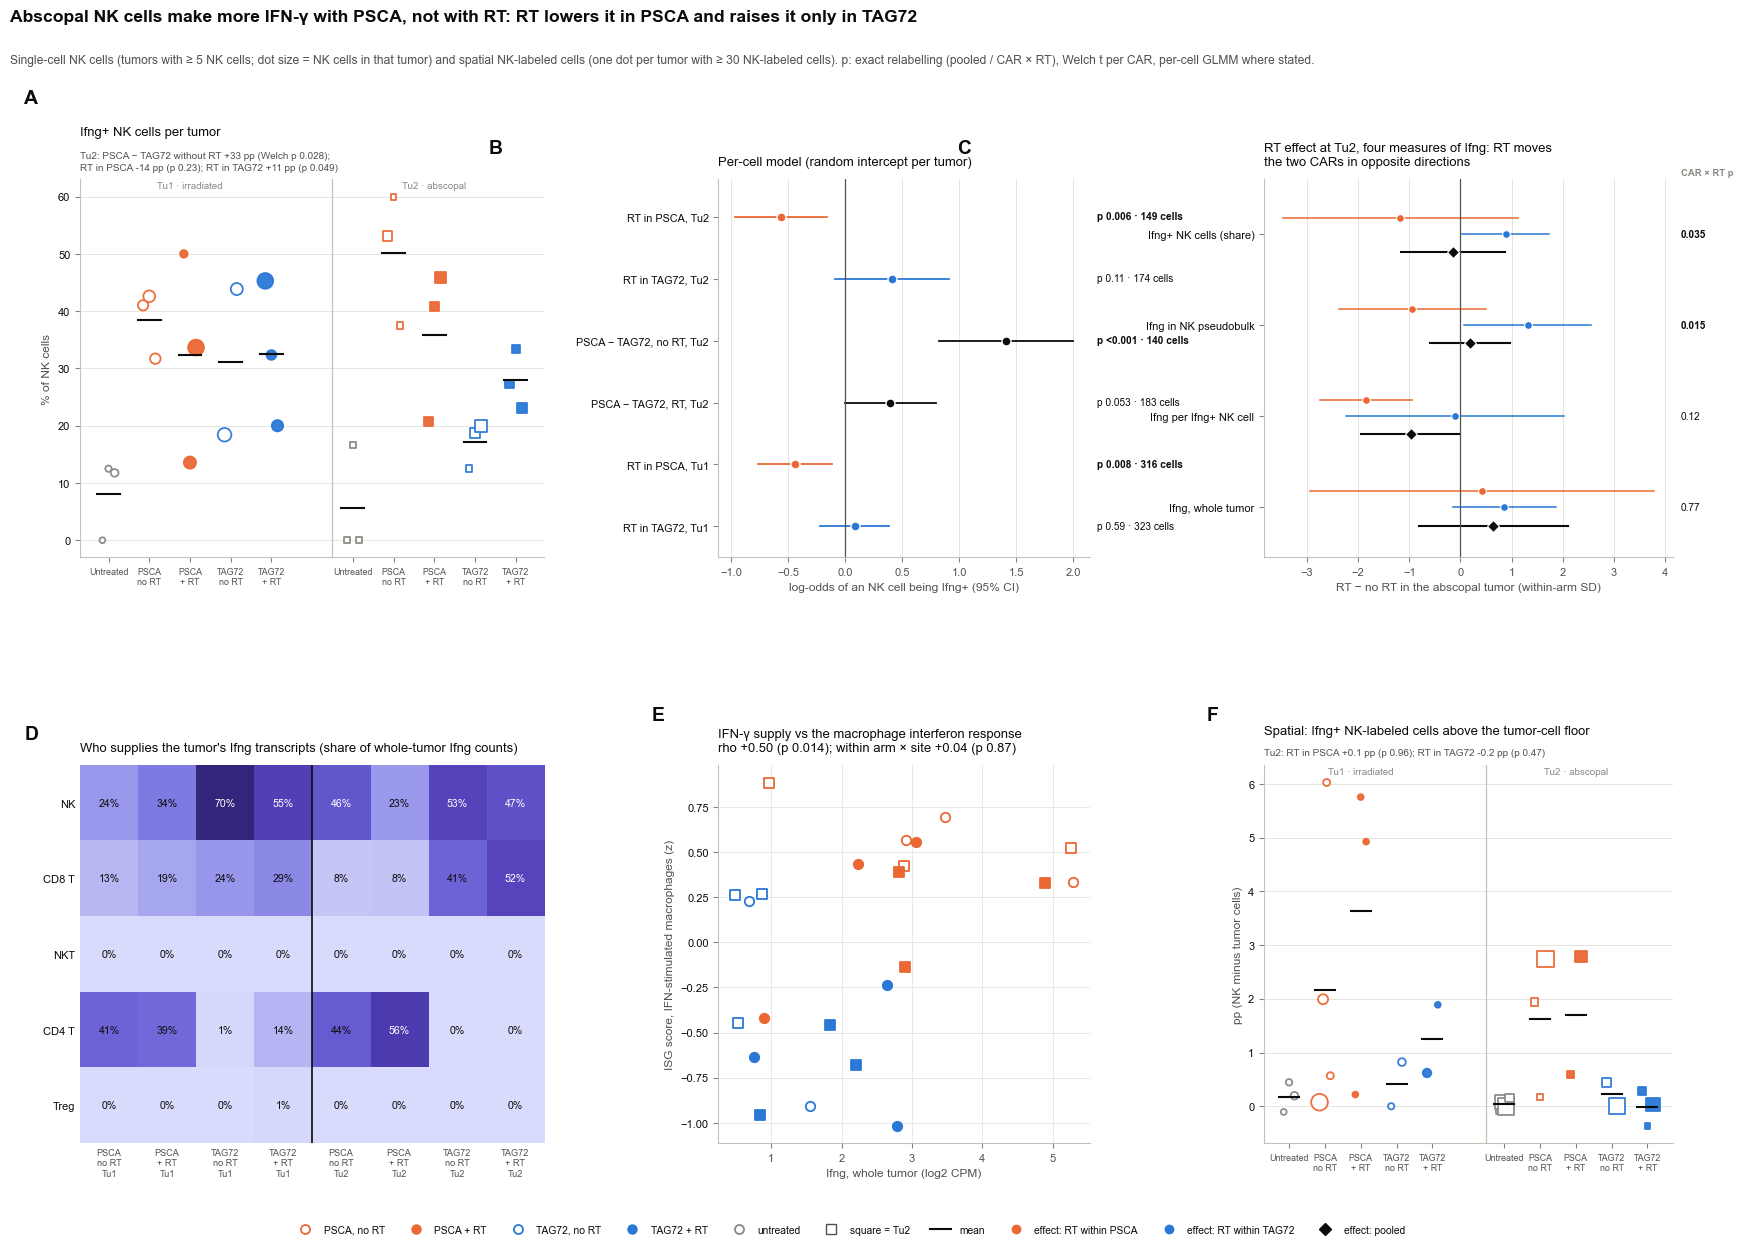

In [10]:
def ge(df, readout, eff, part, k="est"):
    d = df[(df.readout == readout) & (df.effect == eff) & (df.part == part)]
    return d[k].iloc[0] if len(d) else np.nan


fig = plt.figure(figsize=(17.5, 12.6))
gs = GridSpec(2, 3, height_ratios=[1, 1.0], width_ratios=[1.25, 1.0, 1.1], hspace=0.55, wspace=0.42,
              left=0.06, right=0.97, top=0.845, bottom=0.08)
fig.suptitle("Abscopal NK cells make more IFN-γ with PSCA, not with RT: RT lowers it in PSCA and raises it only in TAG72",
             x=0.02, y=0.98, ha="left", fontsize=12.6, weight="bold")
fig.text(0.02, 0.937, f"Single-cell NK cells (tumors with ≥ {MIN_NK} NK cells; dot size = NK cells in that tumor) and spatial NK-labeled "
         "cells (one dot per tumor with ≥ 30 NK-labeled cells). p: exact relabelling (pooled / CAR × RT), Welch t per CAR, per-cell GLMM where stated.",
         fontsize=8.7, color=INK2)
NKF_all = frac_table(NK, ["Ifng"], 1).join(sm)
ax = fig.add_subplot(gs[0, 0])
e_n, p_n = ge(IFNG_EFF, "Ifng+ NK (% of NK)", "PSCA Tu2", "no RT"), ge(IFNG_EFF, "Ifng+ NK (% of NK)", "PSCA Tu2", "no RT", "welch")
e_p, w_p = ge(IFNG_EFF, "Ifng+ NK (% of NK)", "RT Tu2", "PSCA"), ge(IFNG_EFF, "Ifng+ NK (% of NK)", "RT Tu2", "PSCA", "welch")
e_t, w_t = ge(IFNG_EFF, "Ifng+ NK (% of NK)", "RT Tu2", "TAG72"), ge(IFNG_EFF, "Ifng+ NK (% of NK)", "RT Tu2", "TAG72", "welch")
strip_sites(ax, NKF_all["Ifng"] * 100, NKF_all[["arm", "site"]], "Ifng+ NK cells per tumor", ylab="% of NK cells",
            sizes=NKF_all["n"], include_notx=True,
            annot=f"Tu2: PSCA − TAG72 without RT {e_n:+.0f} pp (Welch p {fmt_p(p_n)});\n"
                  f"RT in PSCA {e_p:+.0f} pp (p {fmt_p(w_p)}); RT in TAG72 {e_t:+.0f} pp (p {fmt_p(w_t)})")
ax.text(-0.12, 1.2, "A", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[0, 1]); rows = []
for name in ["RT in PSCA, Tu2", "RT in TAG72, Tu2", "PSCA − TAG72, no RT, Tu2", "PSCA − TAG72, RT, Tu2",
             "RT in PSCA, Tu1", "RT in TAG72, Tu1"]:
    r = GL[(GL.gene == "Ifng") & (GL.comparison == name)]
    if len(r):
        r = r.iloc[0]
        col = INK if "−" in name else (C_PSCA if "PSCA" in name else C_TAG72)
        rows.append((name, r.logodds, r.logodds - 1.96 * r.sd, r.logodds + 1.96 * r.sd, r.p, int(r.n_cells), col))
for i, (name, est, lo, hi, p, n, col) in enumerate(rows):
    ax.plot([lo, hi], [-i, -i], color=col, lw=1.3); ax.plot(est, -i, "o", color=col, ms=6.5, mec="white", zorder=3)
    ax.text(1.02, -i, f"p {fmt_p(p)} · {n} cells", transform=ax.get_yaxis_transform(), va="center", fontsize=7.3,
            weight="bold" if p < 0.05 else "normal")
ax.axvline(0, color=INK2, lw=0.9); ax.set_yticks([-i for i in range(len(rows))]); ax.set_yticklabels([r[0] for r in rows], fontsize=7.8)
ax.set_ylim(-len(rows) + 0.5, 0.6); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("log-odds of an NK cell being Ifng+ (95% CI)")
ax.set_title("Per-cell model (random intercept per tumor)", loc="left", fontsize=9.4, pad=10)
ax.text(-0.62, 1.07, "B", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[0, 2]); rows = []


def sdw_of(v, meta):
    d = pd.DataFrame({"v": v}).join(meta); d = d[d.arm.isin(ARMS4)]
    return float(d.groupby(["arm", "site"]).v.var().mean() ** 0.5)


SDW_IFNG = {"Ifng+ NK (% of NK)": sdw_of(NKF["Ifng"] * 100, NKF[["arm", "site"]]),
            "Ifng, NK pseudobulk (log2 CPM)": sdw_of(nk_ifng_pb, sample_meta(nk_ifng_pb.index)),
            "Ifng level in Ifng+ NK (log1p CP10k)": sdw_of(NKF["ifng_level_pos"], NKF[["arm", "site"]]),
            "Ifng, whole tumor (log2 CPM)": sdw_of(WT_IFNG, WTM)}
for ro, lab_ in [("Ifng+ NK (% of NK)", "Ifng+ NK cells (share)"), ("Ifng, NK pseudobulk (log2 CPM)", "Ifng in NK pseudobulk"),
                 ("Ifng level in Ifng+ NK (log1p CP10k)", "Ifng per Ifng+ NK cell"), ("Ifng, whole tumor (log2 CPM)", "Ifng, whole tumor")]:
    r = eff_row(IFNG_EFF, ro, "RT Tu2", lab_, p_part="CARxRT")
    if r:
        sd_ = SDW_IFNG[ro]
        for k_ in ("psca", "tag", "pooled"): r[k_] = tuple(x / sd_ for x in r[k_])
        rows.append(r)
forest(ax, rows, "RT − no RT in the abscopal tumor (within-arm SD)", p_head="CAR × RT p")
ax.set_title("RT effect at Tu2, four measures of Ifng: RT moves\nthe two CARs in opposite directions", loc="left", fontsize=9.4, pad=10)
ax.text(-0.75, 1.07, "C", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 0])
SRC_SHOW = ["NK", "CD8_T", "NKT", "CD4_T", "Treg"]
SS = SRC_IFNG.reindex(columns=SRC_SHOW).fillna(0).join(WTM)
SS = SS[SS.arm.isin(ARMS4)].groupby(["site", "arm"])[SRC_SHOW].mean().reindex(pd.MultiIndex.from_product([[1, 2], ARMS4]))
im = ax.imshow(SS.values.T * 100, cmap=SEQ, vmin=0, vmax=80, aspect="auto")
for i in range(SS.shape[0]):
    for j in range(len(SRC_SHOW)):
        v = SS.values[i, j] * 100
        ax.text(i, j, f"{v:.0f}%", ha="center", va="center", fontsize=7.6, color="white" if v > 45 else INK)
ax.set_xticks(range(len(SS))); ax.set_xticklabels([f"{ARM_LAB[a]}\nTu{s}" for s, a in SS.index], fontsize=6.6)
ax.set_yticks(range(len(SRC_SHOW))); ax.set_yticklabels(["NK", "CD8 T", "NKT", "CD4 T", "Treg"])
ax.axvline(3.5, color=INK, lw=1.2); ax.tick_params(length=0); [s_.set_visible(False) for s_ in ax.spines.values()]
ax.set_title("Who supplies the tumor's Ifng transcripts (share of whole-tumor Ifng counts)", loc="left", fontsize=9.4, pad=10)
ax.text(-0.12, 1.07, "D", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 1])
for _, r in lk.iterrows():
    col_ = CAR_COL[CAR_OF[r.arm]]
    ax.scatter(r.ifng_wt, r.isg_mac, s=46, marker="o" if r.site == 1 else "s", facecolor=col_ if RT_OF[r.arm] else "white",
               edgecolor=col_, linewidth=1.3, zorder=3)
ax.set_xlabel("Ifng, whole tumor (log2 CPM)"); ax.set_ylabel("ISG score, IFN-stimulated macrophages (z)")
ax.grid(True, color=GRID, lw=0.5); ax.set_axisbelow(True)
ax.set_title(f"IFN-γ supply vs the macrophage interferon response\nrho {rho_raw.correlation:+.2f} (p {fmt_p(rho_raw.pvalue)}); "
             f"within arm × site {rho_within.correlation:+.2f} (p {fmt_p(rho_within.pvalue)})", loc="left", fontsize=9.4, pad=10)
ax.text(-0.18, 1.12, "E", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 2])
spe = SP_IFNG[SP_IFNG.readout == "spatial: NK Ifng+ minus tumor-cell floor (pp)"]
strip_sites(ax, SPI.nk_ifng_excess * 100, SPI[["arm", "site"]], "Spatial: Ifng+ NK-labeled cells above the tumor-cell floor",
            ylab="pp (NK minus tumor cells)", sizes=SPI.n_nk / 20, include_notx=True,
            annot=f"Tu2: RT in PSCA {ge(SP_IFNG, 'spatial: NK Ifng+ minus tumor-cell floor (pp)', 'RT Tu2', 'PSCA'):+.1f} pp (p "
                  f"{fmt_p(ge(SP_IFNG, 'spatial: NK Ifng+ minus tumor-cell floor (pp)', 'RT Tu2', 'PSCA', 'welch'))}); RT in TAG72 "
                  f"{ge(SP_IFNG, 'spatial: NK Ifng+ minus tumor-cell floor (pp)', 'RT Tu2', 'TAG72'):+.1f} pp (p "
                  f"{fmt_p(ge(SP_IFNG, 'spatial: NK Ifng+ minus tumor-cell floor (pp)', 'RT Tu2', 'TAG72', 'welch'))})")
ax.text(-0.14, 1.12, "F", transform=ax.transAxes, fontsize=14, weight="bold")
legend_arms(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureN1_ifng.{ext}", bbox_inches="tight")
plt.show()

## 10. Figure N2 — NK phenotype: what RT changes, per CAR and site

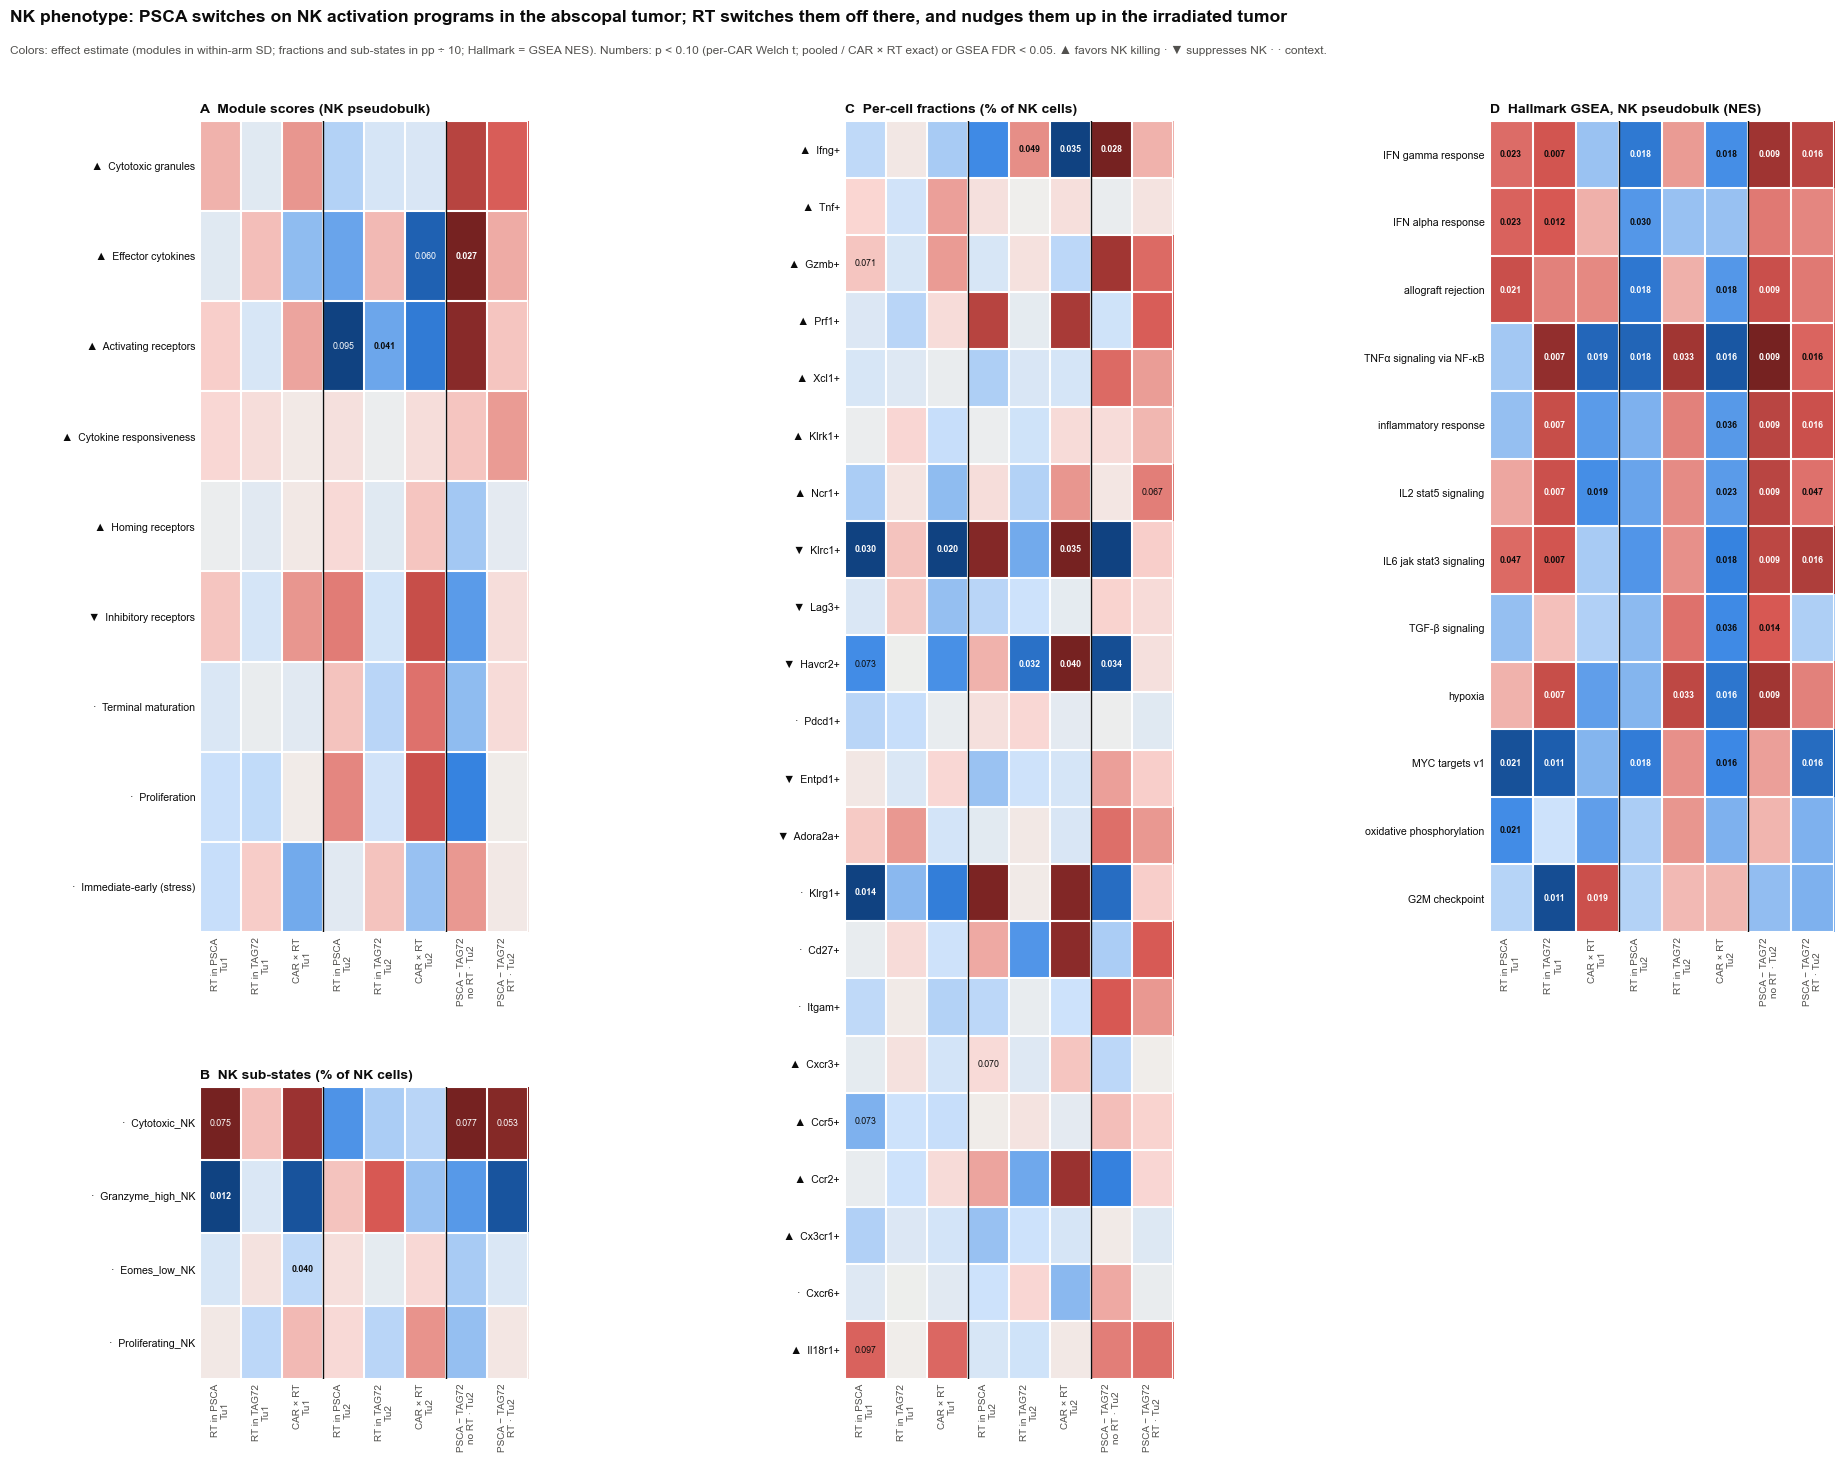

In [11]:
VIEWS = [("RT Tu1", "PSCA", "RT in PSCA\nTu1"), ("RT Tu1", "TAG72", "RT in TAG72\nTu1"), ("RT Tu1", "CARxRT", "CAR × RT\nTu1"),
         ("RT Tu2", "PSCA", "RT in PSCA\nTu2"), ("RT Tu2", "TAG72", "RT in TAG72\nTu2"), ("RT Tu2", "CARxRT", "CAR × RT\nTu2"),
         ("PSCA Tu2", "no RT", "PSCA − TAG72\nno RT · Tu2"), ("PSCA Tu2", "RT", "PSCA − TAG72\nRT · Tu2")]
ROWS_MOD = [m for m in NK_MODULES if m in NKS.columns]
ROWS_FR = [f"{g}+ (% of NK)" for g in ["Ifng", "Tnf", "Gzmb", "Prf1", "Xcl1", "Klrk1", "Ncr1", "Klrc1", "Lag3", "Havcr2", "Pdcd1",
                                         "Entpd1", "Adora2a", "Klrg1", "Cd27", "Itgam", "Cxcr3", "Ccr5", "Ccr2", "Cx3cr1", "Cxcr6", "Il18r1"]
           if f"{g}+ (% of NK)" in set(PHENO.readout)]
ROWS_SUB = [f"{s} (% of NK)" for s in SUBS_NK]
HV = [(1, "RT_in_PSCA", "RT in PSCA\nTu1"), (1, "RT_in_TAG72", "RT in TAG72\nTu1"), (1, "CARxRT", "CAR × RT\nTu1"),
      (2, "RT_in_PSCA", "RT in PSCA\nTu2"), (2, "RT_in_TAG72", "RT in TAG72\nTu2"), (2, "CARxRT", "CAR × RT\nTu2"),
      (2, "PSCA_noRT", "PSCA − TAG72\nno RT · Tu2"), (2, "PSCA_RT", "PSCA − TAG72\nRT · Tu2")]
HROWS = ["HALLMARK_INTERFERON_GAMMA_RESPONSE", "HALLMARK_INTERFERON_ALPHA_RESPONSE", "HALLMARK_ALLOGRAFT_REJECTION",
         "HALLMARK_TNFA_SIGNALING_VIA_NFKB", "HALLMARK_INFLAMMATORY_RESPONSE", "HALLMARK_IL2_STAT5_SIGNALING",
         "HALLMARK_IL6_JAK_STAT3_SIGNALING", "HALLMARK_TGF_BETA_SIGNALING", "HALLMARK_HYPOXIA", "HALLMARK_MYC_TARGETS_V1",
         "HALLMARK_OXIDATIVE_PHOSPHORYLATION", "HALLMARK_G2M_CHECKPOINT"]


def view_mat(rows, k):
    out = []
    for r in rows:
        line = []
        for e, p_, _ in VIEWS:
            d = PHENO[(PHENO.readout == r) & (PHENO.effect == e) & (PHENO.part == p_)]
            line.append(d[k].iloc[0] if len(d) else np.nan)
        out.append(line)
    return pd.DataFrame(out, index=rows, columns=[t for _, _, t in VIEWS]).astype(float)


def tag(r):
    o = ORI.get(r, GENE_ORI.get(r.split("+")[0], 0))
    return {1: "▲", -1: "▼", 0: "·"}[o]


fig = plt.figure(figsize=(19, 14.8))
gs = GridSpec(2, 3, height_ratios=[1.0, 0.36], width_ratios=[1.0, 1.0, 1.05], hspace=0.28, wspace=0.95,
              left=0.12, right=0.98, top=0.9, bottom=0.05)
fig.suptitle("NK phenotype: PSCA switches on NK activation programs in the abscopal tumor; RT switches them off there, and nudges "
             "them up in the irradiated tumor", x=0.02, y=0.975, ha="left", fontsize=12.6, weight="bold")
fig.text(0.02, 0.945, "Colors: effect estimate (modules in within-arm SD; fractions and sub-states in pp ÷ 10; Hallmark = GSEA NES). "
         "Numbers: p < 0.10 (per-CAR Welch t; pooled / CAR × RT exact) or GSEA FDR < 0.05. ▲ favors NK killing · ▼ suppresses NK · · context.",
         fontsize=8.6, color=INK2)
for pos, rows, title, scale in [(gs[0, 0], ROWS_MOD, "A  Module scores (NK pseudobulk)", 1.0),
                                (gs[1, 0], ROWS_SUB, "B  NK sub-states (% of NK cells)", 0.1),
                                (gs[:, 1], ROWS_FR, "C  Per-cell fractions (% of NK cells)", 0.1)]:
    ax = fig.add_subplot(pos)
    E, P = view_mat(rows, "est") * scale, view_mat(rows, "p_use")
    heat(ax, E, P, vmax=2.5, p_show=0.10, fs=6.3, row_labels=[f"{tag(r)}  {r.replace(' (% of NK)', '')}" for r in rows])
    ax.tick_params(axis="x", labelrotation=90)
    ax.set_title(title, loc="left", fontsize=10, weight="bold")
    ax.axvline(2.5, color=INK, lw=1.0); ax.axvline(5.5, color=INK, lw=1.0)
ax = fig.add_subplot(gs[0, 2])
HN = pd.DataFrame([[NKGS[(NKGS.site == si) & (NKGS.contrast == c) & (NKGS.pathway == h)].NES.squeeze() if
                    len(NKGS[(NKGS.site == si) & (NKGS.contrast == c) & (NKGS.pathway == h)]) else np.nan for si, c, _ in HV]
                   for h in HROWS], index=HROWS, columns=[t for _, _, t in HV]).astype(float)
HQ = pd.DataFrame([[NKGS[(NKGS.site == si) & (NKGS.contrast == c) & (NKGS.pathway == h)].FDR.squeeze() if
                    len(NKGS[(NKGS.site == si) & (NKGS.contrast == c) & (NKGS.pathway == h)]) else np.nan for si, c, _ in HV]
                   for h in HROWS], index=HROWS, columns=HN.columns).astype(float)
heat(ax, HN, HQ, vmax=3.0, p_show=0.05, fs=6.3,
     row_labels=[h.replace("HALLMARK_", "").replace("_", " ").lower().replace("tnfa", "TNFα").replace("nfkb", "NF-κB")
                 .replace("interferon", "IFN").replace("il2", "IL2").replace("il6", "IL6").replace("myc", "MYC").replace("g2m", "G2M")
                 .replace("tgf beta", "TGF-β") for h in HROWS])
ax.axvline(2.5, color=INK, lw=1.0); ax.axvline(5.5, color=INK, lw=1.0); ax.tick_params(axis="x", labelrotation=90)
ax.set_title("D  Hallmark GSEA, NK pseudobulk (NES)", loc="left", fontsize=10, weight="bold")
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureN2_nk_phenotype.{ext}", bbox_inches="tight")
plt.show()

## 11. Figure N3 — Is the CD73 / adenosine axis still there in the abscopal tumor?

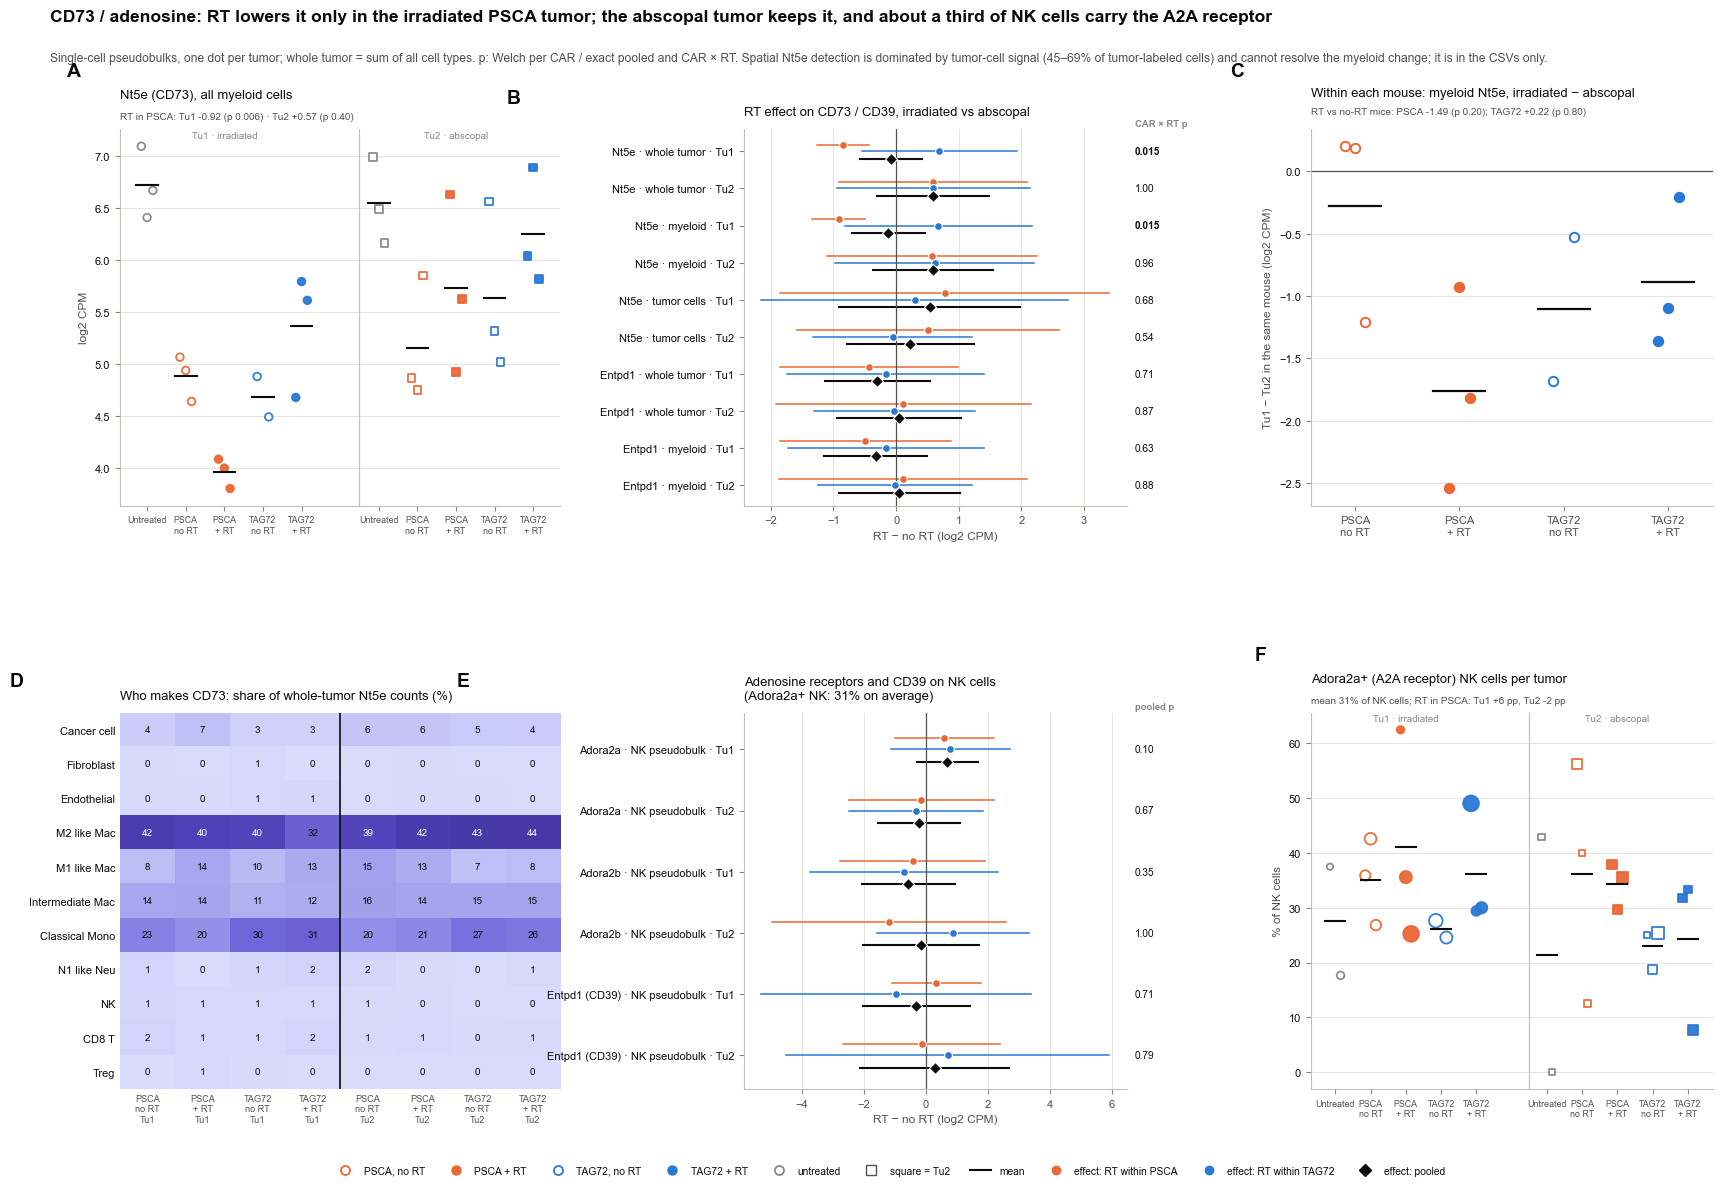

In [12]:
fig = plt.figure(figsize=(17.5, 12))
gs = GridSpec(2, 3, height_ratios=[1, 1], width_ratios=[1.15, 1.0, 1.05], hspace=0.55, wspace=0.45, left=0.06, right=0.97, top=0.88, bottom=0.08)
fig.suptitle("CD73 / adenosine: RT lowers it only in the irradiated PSCA tumor; the abscopal tumor keeps it, and about a third of NK cells carry the A2A receptor",
             x=0.02, y=0.98, ha="left", fontsize=12.6, weight="bold")
fig.text(0.02, 0.937, "Single-cell pseudobulks, one dot per tumor; whole tumor = sum of all cell types. p: Welch per CAR / exact pooled and "
         "CAR × RT. Spatial Nt5e detection is dominated by tumor-cell signal (45–69% of tumor-labeled cells) and cannot resolve the myeloid "
         "change; it is in the CSVs only.", fontsize=8.7, color=INK2)
ax = fig.add_subplot(gs[0, 0])
strip_sites(ax, MYL["Nt5e"], sample_meta(MYL.index), "Nt5e (CD73), all myeloid cells", ylab="log2 CPM", include_notx=True,
            annot=f"RT in PSCA: Tu1 {ge(ADO_EFF, 'Nt5e, all myeloid cells (log2 CPM)', 'RT Tu1', 'PSCA'):+.2f} (p "
                  f"{fmt_p(ge(ADO_EFF, 'Nt5e, all myeloid cells (log2 CPM)', 'RT Tu1', 'PSCA', 'welch'))}) · Tu2 "
                  f"{ge(ADO_EFF, 'Nt5e, all myeloid cells (log2 CPM)', 'RT Tu2', 'PSCA'):+.2f} (p "
                  f"{fmt_p(ge(ADO_EFF, 'Nt5e, all myeloid cells (log2 CPM)', 'RT Tu2', 'PSCA', 'welch'))})")
ax.text(-0.12, 1.14, "A", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[0, 1]); rows = []
for ro, lab_ in [("Nt5e, whole tumor (log2 CPM)", "Nt5e · whole tumor"), ("Nt5e, all myeloid cells (log2 CPM)", "Nt5e · myeloid"),
                 ("Nt5e, Cancer cell (log2 CPM)", "Nt5e · tumor cells"), ("Entpd1, whole tumor (log2 CPM)", "Entpd1 · whole tumor"),
                 ("Entpd1, all myeloid cells (log2 CPM)", "Entpd1 · myeloid")]:
    for eff, t in [("RT Tu1", "Tu1"), ("RT Tu2", "Tu2")]:
        r = eff_row(ADO_EFF, ro, eff, f"{lab_} · {t}", p_part="CARxRT")
        if r: rows.append(r)
forest(ax, rows, "RT − no RT (log2 CPM)", p_head="CAR × RT p")
ax.set_title("RT effect on CD73 / CD39, irradiated vs abscopal", loc="left", fontsize=9.4, pad=10)
ax.text(-0.62, 1.07, "B", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[0, 2])
w = WMOUSE["Nt5e, all myeloid"]
for x_, (arm, lab_) in enumerate([("CyPSCA", "PSCA\nno RT"), ("RTCyPSCA", "PSCA\n+ RT"), ("CyT72", "TAG72\nno RT"), ("RTCyT72", "TAG72\n+ RT")]):
    v = w[w.arm == arm].d; col_ = CAR_COL[CAR_OF[arm]]
    ax.scatter(np.full(len(v), x_) + np.linspace(-0.1, 0.1, len(v)), v, s=46, facecolor=col_ if RT_OF[arm] else "white",
               edgecolor=col_, lw=1.4, zorder=3)
    if len(v): ax.plot([x_ - 0.25, x_ + 0.25], [v.mean()] * 2, color=INK, lw=1.6)
ax.axhline(0, color=INK2, lw=0.9); ax.set_xticks(range(4)); ax.set_xticklabels(["PSCA\nno RT", "PSCA\n+ RT", "TAG72\nno RT", "TAG72\n+ RT"])
ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_ylabel("Tu1 − Tu2 in the same mouse (log2 CPM)")
dd = DID[DID.readout == "Nt5e, all myeloid"].set_index("part")
ax.set_title("Within each mouse: myeloid Nt5e, irradiated − abscopal", loc="left", fontsize=9.4, pad=24)
ax.text(0, 1.04, f"RT vs no-RT mice: PSCA {dd.loc['PSCA', 'did']:+.2f} (p {fmt_p(dd.loc['PSCA', 'p'])}); "
        f"TAG72 {dd.loc['TAG72', 'did']:+.2f} (p {fmt_p(dd.loc['TAG72', 'p'])})", transform=ax.transAxes, fontsize=7.2, color=INK2)
ax.text(-0.2, 1.14, "C", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 0])
SHOW = ["Cancer_cell", "Fibroblast", "Endothelial", "M2_like_Mac", "M1_like_Mac", "Intermediate_Mac", "Classical_Mono", "N1_like_Neu", "NK", "CD8_T", "Treg"]
SC_ = CON_NT5E.reindex(columns=SHOW).fillna(0).join(WTM)
SC_ = SC_[SC_.arm.isin(ARMS4)].groupby(["site", "arm"])[SHOW].mean().reindex(pd.MultiIndex.from_product([[1, 2], ARMS4]))
ax.imshow(SC_.values.T * 100, cmap=SEQ, vmin=0, vmax=60, aspect="auto")
for i in range(SC_.shape[0]):
    for j in range(len(SHOW)):
        v = SC_.values[i, j] * 100
        ax.text(i, j, f"{v:.0f}", ha="center", va="center", fontsize=7.2, color="white" if v > 35 else INK)
ax.set_xticks(range(len(SC_))); ax.set_xticklabels([f"{ARM_LAB[a]}\nTu{s}" for s, a in SC_.index], fontsize=6.6)
ax.set_yticks(range(len(SHOW))); ax.set_yticklabels([s.replace("_", " ") for s in SHOW])
ax.axvline(3.5, color=INK, lw=1.2); ax.tick_params(length=0); [s_.set_visible(False) for s_ in ax.spines.values()]
ax.set_title("Who makes CD73: share of whole-tumor Nt5e counts (%)", loc="left", fontsize=9.4, pad=10)
ax.text(-0.25, 1.07, "D", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 1]); rows = []
for ro, lab_ in [("Adora2a, NK pseudobulk (log2 CPM)", "Adora2a · NK pseudobulk"), ("Adora2b, NK pseudobulk (log2 CPM)", "Adora2b · NK pseudobulk"),
                 ("Entpd1, NK pseudobulk (log2 CPM)", "Entpd1 (CD39) · NK pseudobulk")]:
    for eff, t in [("RT Tu1", "Tu1"), ("RT Tu2", "Tu2")]:
        r = eff_row(ADO_EFF, ro, eff, f"{lab_} · {t}")
        if r: rows.append(r)
forest(ax, rows, "RT − no RT (log2 CPM)", p_head="pooled p")
a2a = NKF["Adora2a"].mul(100).groupby([NKF.arm, NKF.site]).mean() if "Adora2a" in NKF else None
ax.set_title("Adenosine receptors and CD39 on NK cells"
             + (f"\n(Adora2a+ NK: {a2a.mean():.0f}% on average)" if a2a is not None else ""), loc="left", fontsize=9.4, pad=10)
ax.text(-0.75, 1.07, "E", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 2])
a2 = PHENO[(PHENO.readout == "Adora2a+ (% of NK)")]
strip_sites(ax, NKF["Adora2a"] * 100, NKF[["arm", "site"]], "Adora2a+ (A2A receptor) NK cells per tumor", ylab="% of NK cells",
            sizes=NKF["n"], include_notx=True,
            annot=f"mean {NKF.Adora2a.mean() * 100:.0f}% of NK cells; RT in PSCA: Tu1 "
                  f"{ge(PHENO, 'Adora2a+ (% of NK)', 'RT Tu1', 'PSCA'):+.0f} pp, Tu2 {ge(PHENO, 'Adora2a+ (% of NK)', 'RT Tu2', 'PSCA'):+.0f} pp")
ax.text(-0.14, 1.14, "F", transform=ax.transAxes, fontsize=14, weight="bold")
legend_arms(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureN3_adenosine.{ext}", bbox_inches="tight")
plt.show()

## 12. Figure N4 — The NK recruitment environment

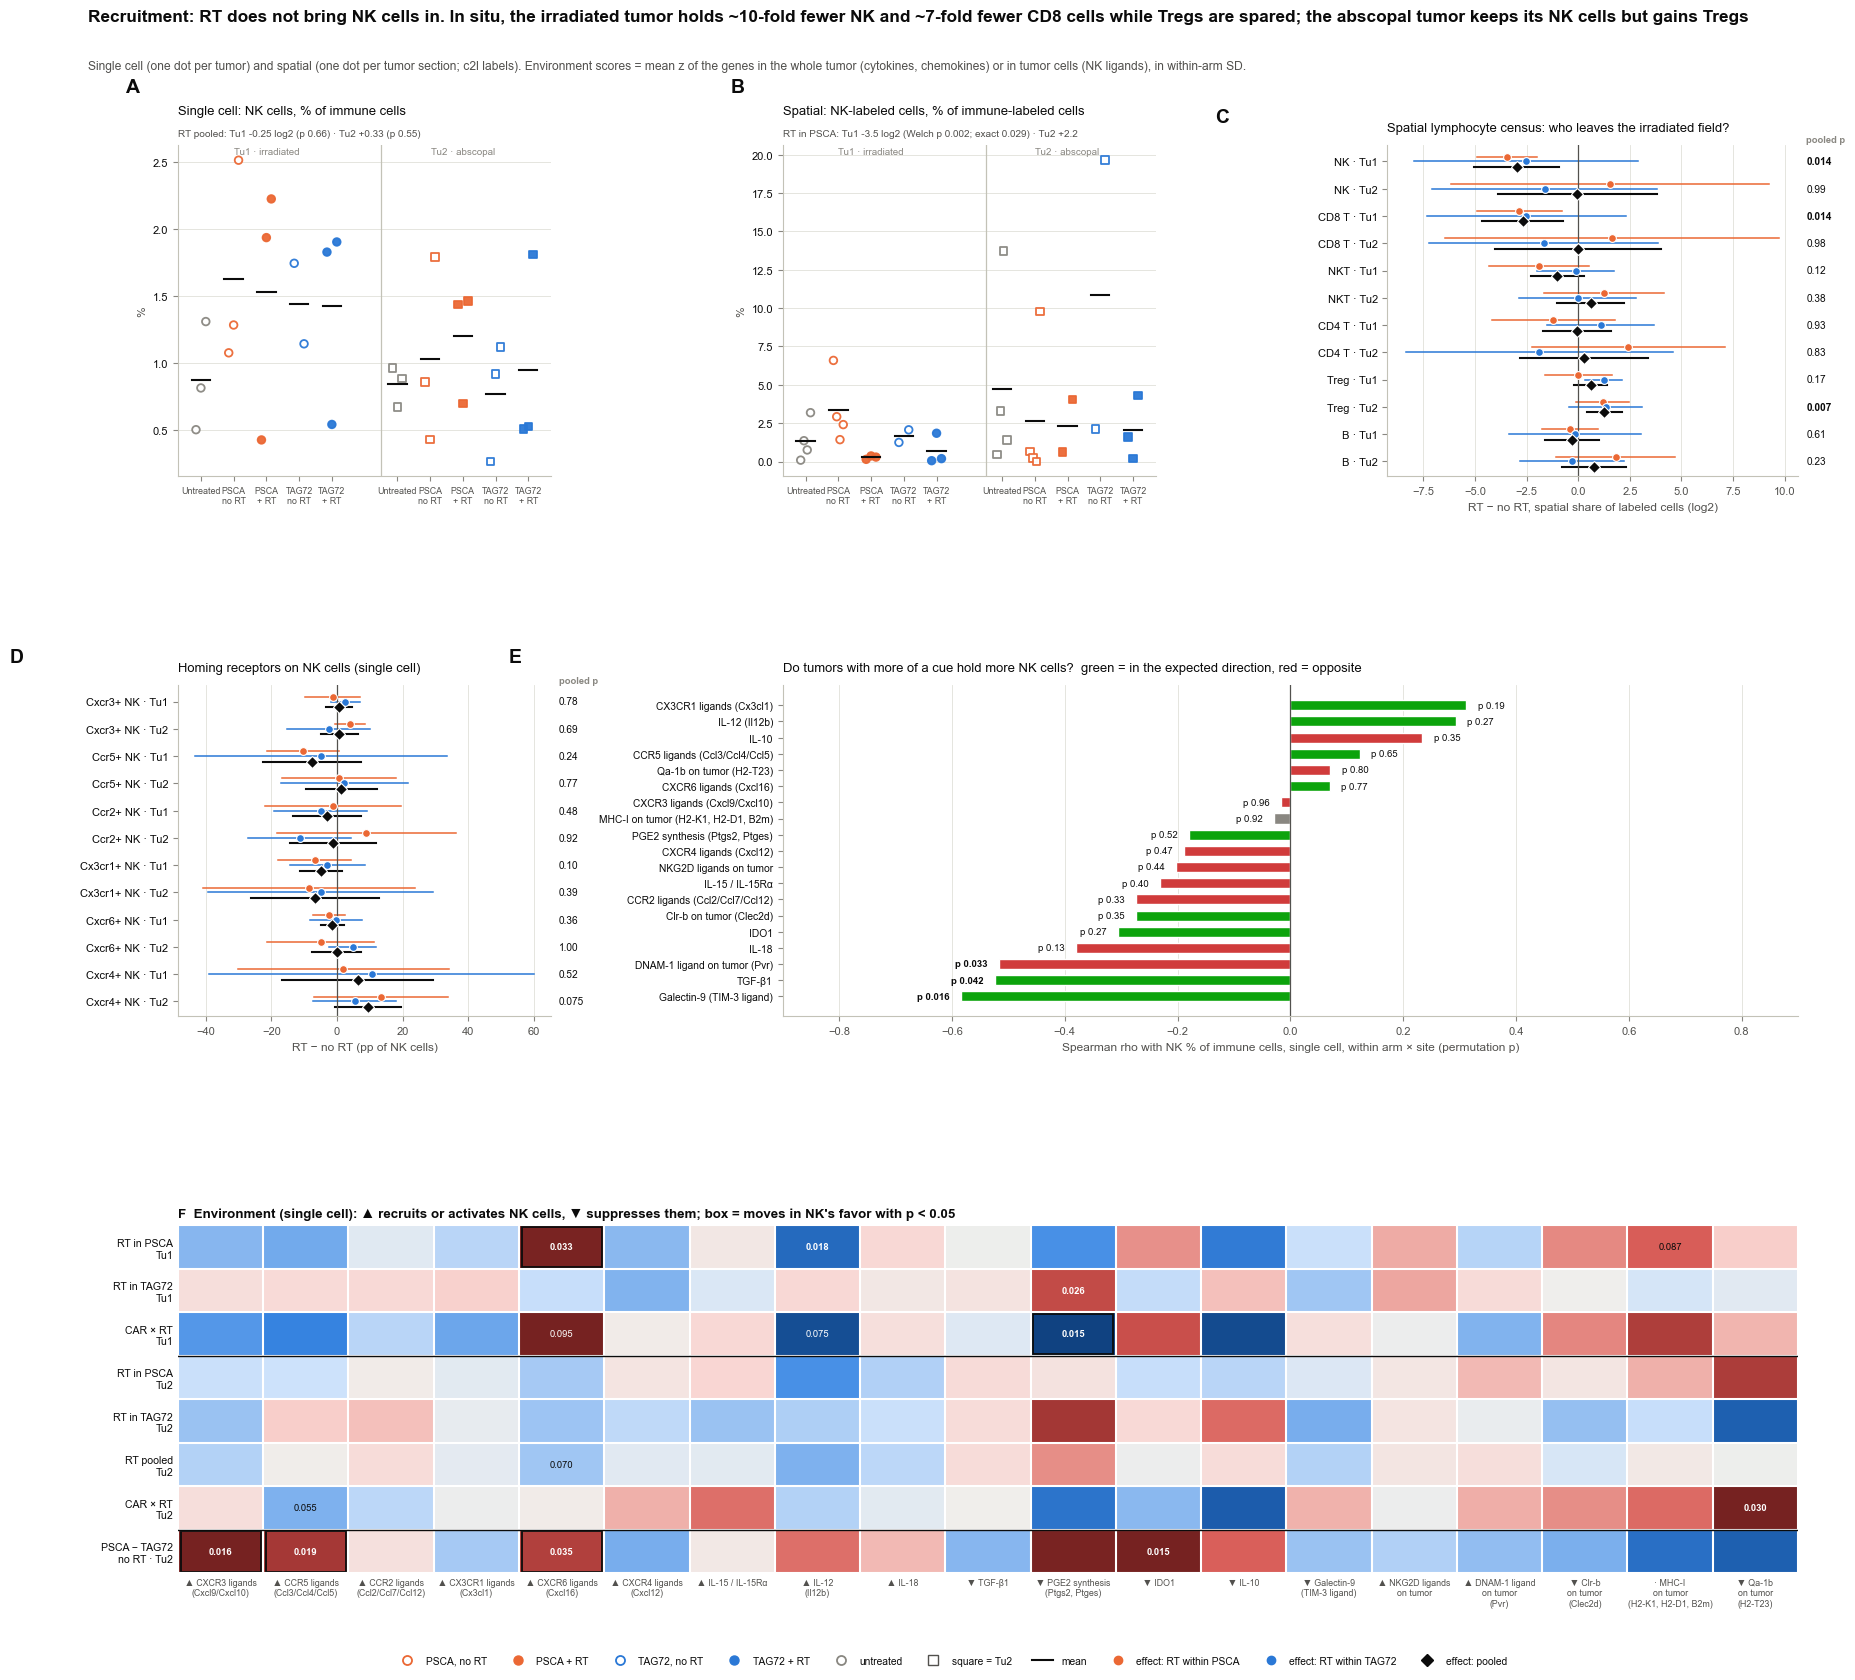

In [13]:
fig = plt.figure(figsize=(18, 17))
gs = GridSpec(3, 3, height_ratios=[1, 1, 1.05], width_ratios=[1.0, 1.0, 1.1], hspace=0.62, wspace=0.6,
              left=0.07, right=0.97, top=0.9, bottom=0.06)
fig.suptitle("Recruitment: RT does not bring NK cells in. In situ, the irradiated tumor holds ~10-fold fewer NK and ~7-fold fewer CD8 "
             "cells while Tregs are spared; the abscopal tumor keeps its NK cells but gains Tregs", x=0.02, y=0.98, ha="left",
             fontsize=12.4, weight="bold")
fig.text(0.02, 0.945, "Single cell (one dot per tumor) and spatial (one dot per tumor section; c2l labels). Environment scores = mean z of the "
         "genes in the whole tumor (cytokines, chemokines) or in tumor cells (NK ligands), in within-arm SD.", fontsize=8.7, color=INK2)
ax = fig.add_subplot(gs[0, 0])
strip_sites(ax, ABUND.nk_pct_immune, ABUND[["arm", "site"]], "Single cell: NK cells, % of immune cells", ylab="%", include_notx=True,
            annot=f"RT pooled: Tu1 {ge(REC, 'NK, % of immune cells (log2)', 'RT Tu1', 'pooled'):+.2f} log2 (p "
                  f"{fmt_p(ge(REC, 'NK, % of immune cells (log2)', 'RT Tu1', 'pooled', 'p'))}) · Tu2 "
                  f"{ge(REC, 'NK, % of immune cells (log2)', 'RT Tu2', 'pooled'):+.2f} (p {fmt_p(ge(REC, 'NK, % of immune cells (log2)', 'RT Tu2', 'pooled', 'p'))})")
ax.text(-0.14, 1.16, "A", transform=ax.transAxes, fontsize=14, weight="bold")
ax = fig.add_subplot(gs[0, 1])
strip_sites(ax, SPAB.nk_pct_immune, SPAB[["arm", "site"]], "Spatial: NK-labeled cells, % of immune-labeled cells", ylab="%", include_notx=True,
            annot=f"RT in PSCA: Tu1 {ge(REC, 'spatial: NK, % of immune cells (log2)', 'RT Tu1', 'PSCA'):+.1f} log2 (Welch p "
                  f"{fmt_p(ge(REC, 'spatial: NK, % of immune cells (log2)', 'RT Tu1', 'PSCA', 'welch'))}; exact "
                  f"{fmt_p(ge(REC, 'spatial: NK, % of immune cells (log2)', 'RT Tu1', 'PSCA', 'p'))}) · Tu2 "
                  f"{ge(REC, 'spatial: NK, % of immune cells (log2)', 'RT Tu2', 'PSCA'):+.1f}")
ax.text(-0.14, 1.16, "B", transform=ax.transAxes, fontsize=14, weight="bold")
ax = fig.add_subplot(gs[0, 2]); rows = []
for ct, lab_ in [("NK", "NK"), ("CD8_T", "CD8 T"), ("NKT", "NKT"), ("CD4_T", "CD4 T"), ("Treg", "Treg"), ("B", "B")]:
    for eff, t in [("RT Tu1", "Tu1"), ("RT Tu2", "Tu2")]:
        r = eff_row(REC, f"spatial: {ct} (% of labeled, log2)", eff, f"{lab_} · {t}", p_part="pooled")
        if r: rows.append(r)
forest(ax, rows, "RT − no RT, spatial share of labeled cells (log2)", p_head="pooled p")
ax.set_title("Spatial lymphocyte census: who leaves the irradiated field?", loc="left", fontsize=9.4, pad=10)
ax.text(-0.42, 1.07, "C", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 0]); rows = []
for g in ["Cxcr3", "Ccr5", "Ccr2", "Cx3cr1", "Cxcr6", "Cxcr4"]:
    for eff, t in [("RT Tu1", "Tu1"), ("RT Tu2", "Tu2")]:
        r = eff_row(PHENO, f"{g}+ (% of NK)", eff, f"{g}+ NK · {t}")
        if r: rows.append(r)
forest(ax, rows, "RT − no RT (pp of NK cells)", p_head="pooled p")
ax.set_title("Homing receptors on NK cells (single cell)", loc="left", fontsize=9.4, pad=10)
ax.text(-0.45, 1.07, "D", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[1, 1:])
A_ = ASSOC.sort_values("rho_within")
ax.barh(np.arange(len(A_)), A_.rho_within, color=[S_GOOD if (ENV_SCORES[r][0] * v > 0) else (S_CRIT if ENV_SCORES[r][0] * v < 0 else MUTED)
                                                  for r, v in zip(A_.readout, A_.rho_within)], height=0.62, edgecolor="white")
for i, r in enumerate(A_.itertuples()):
    ax.text(r.rho_within + (0.02 if r.rho_within >= 0 else -0.02), i, f"p {fmt_p(r.p_within_perm)}", va="center",
            ha="left" if r.rho_within >= 0 else "right", fontsize=6.9, weight="bold" if r.p_within_perm < 0.05 else "normal")
ax.set_yticks(np.arange(len(A_))); ax.set_yticklabels(A_.readout, fontsize=7.4); ax.axvline(0, color=INK2, lw=0.9)
ax.set_xlim(-0.9, 0.9); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("Spearman rho with NK % of immune cells, single cell, within arm × site (permutation p)")
ax.set_title("Do tumors with more of a cue hold more NK cells?  green = in the expected direction, red = opposite",
             loc="left", fontsize=9.4, pad=10)
ax.text(-0.27, 1.07, "E", transform=ax.transAxes, fontsize=14, weight="bold")

ax = fig.add_subplot(gs[2, :])
ENV_ROWS = list(ENV_SCORES)
EV = [("RT Tu1", "PSCA", "RT in PSCA\nTu1"), ("RT Tu1", "TAG72", "RT in TAG72\nTu1"), ("RT Tu1", "CARxRT", "CAR × RT\nTu1"),
      ("RT Tu2", "PSCA", "RT in PSCA\nTu2"), ("RT Tu2", "TAG72", "RT in TAG72\nTu2"), ("RT Tu2", "pooled", "RT pooled\nTu2"),
      ("RT Tu2", "CARxRT", "CAR × RT\nTu2"), ("PSCA Tu2", "no RT", "PSCA − TAG72\nno RT · Tu2")]


def rec_get(r, e, p_, k):
    d = REC[(REC.readout == r) & (REC.effect == e) & (REC.part == p_)]
    return d[k].iloc[0] if len(d) else np.nan


EM = pd.DataFrame([[rec_get(r, e, p_, "est") for e, p_, _ in EV] for r in ENV_ROWS], index=ENV_ROWS, columns=[t for _, _, t in EV]).T
EP = pd.DataFrame([[rec_get(r, e, p_, "p_use") for e, p_, _ in EV] for r in ENV_ROWS], index=ENV_ROWS, columns=EM.index).T
oris = pd.Series([ENV_SCORES[r][0] for r in ENV_ROWS], index=ENV_ROWS)
BOX = (EM.mul(oris, axis=1) > 0) & (EP < 0.05)
heat(ax, EM, EP, vmax=2.5, p_show=0.10, fs=6.8, box=BOX,
     col_labels=[f"{ {1: '▲', -1: '▼', 0: '·'}[ENV_SCORES[r][0]]} {r}".replace(" (", "\n(").replace(" on tumor", "\non tumor") for r in ENV_ROWS])
ax.tick_params(axis="x", labelrotation=0, labelsize=6.4)
ax.axhline(2.5, color=INK, lw=1.0); ax.axhline(6.5, color=INK, lw=1.0)
ax.set_title("F  Environment (single cell): ▲ recruits or activates NK cells, ▼ suppresses them; box = moves in NK's favor with p < 0.05",
             loc="left", fontsize=9.6, weight="bold")
legend_arms(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureN4_recruitment.{ext}", bbox_inches="tight")
plt.show()

## 13. Scorecard — NK-relevant RT effects against chance

In [14]:
RT_PARTS = [(e, p) for e in ["RT Tu1", "RT Tu2"] for p in ["PSCA", "TAG72", "pooled", "CARxRT"]]
def keep_rt(df): return df[[(e, p) in RT_PARTS for e, p in zip(df.effect, df.part)]].copy()


SC_ALL = []
for df, fam in [(PHENO, None), (REC, None), (ADO_EFF, "adenosine"), (IFNG_EFF, "IFN-γ")]:
    d = keep_rt(df)
    if fam: d["family"] = fam
    if "orientation" not in d: d["orientation"] = 0
    SC_ALL.append(d)
SC_ALL = pd.concat(SC_ALL, ignore_index=True)
# drop readouts that duplicate another family's measurement (same data, counted once)
SC_ALL = SC_ALL[~SC_ALL.readout.isin(["Ifng+ NK (% of NK)", "Ifng, NK pseudobulk (log2 CPM)", "spatial: NK (% of labeled, log2)"])]
ado_ori = {"Nt5e": -1, "Entpd1": -1, "Adora2a": -1, "Adora2b": -1}
SC_ALL.loc[SC_ALL.family == "adenosine", "orientation"] = [ado_ori.get(r.split(",")[0], 0) for r in SC_ALL.loc[SC_ALL.family == "adenosine", "readout"]]
SC_ALL.loc[SC_ALL.family == "IFN-γ", "orientation"] = 1
SC_ALL["site_"] = SC_ALL.effect.str[-1].astype(int)
SC_ALL["ieg_r"] = [IEGR.get((r, s), np.nan) for r, s in zip(SC_ALL.readout, SC_ALL.site_)]
SC_ALL["tracks_IEG"] = SC_ALL.ieg_r.abs() >= 0.5
SC_ALL["advantage"] = SC_ALL.orientation * SC_ALL.est
SC_ALL["call"] = np.where(SC_ALL.orientation == 0, "context", np.where(SC_ALL.advantage > 0, "advantage", "against"))
SC_ALL["contrast"] = SC_ALL.effect.str.replace("RT ", "") + " · " + SC_ALL.part.map({"PSCA": "RT in PSCA", "TAG72": "RT in TAG72",
                                                                                     "pooled": "RT pooled", "CARxRT": "CAR × RT"})
SC_ALL.to_csv(OUT/"scorecard_all_tests.csv", index=False)
CH = SC_ALL.groupby(["family", "contrast"]).agg(tests=("p_use", "count"), p05=("p_use", lambda x: int((x < 0.05).sum())))
CH["expected"] = (CH.tests * 0.05).round(1)
CH = CH.join(SC_ALL[SC_ALL.p_use < 0.05].groupby(["family", "contrast", "call"]).size().unstack(fill_value=0)).fillna(0)
CH.to_csv(OUT/"scorecard_chance.csv")
HITS = SC_ALL[(SC_ALL.p_use < 0.05) & (SC_ALL.call != "context")].sort_values("p_use")
HITS.to_csv(OUT/"scorecard_hits.csv", index=False)
print("NK hits vs chance:"); print(CH.to_string())
print("\nTop hits:"); print(HITS.head(30)[["family", "readout", "contrast", "est", "p_use", "call", "ieg_r"]].round(3).to_string(index=False))

NK hits vs chance:
                                        tests  p05  expected  advantage  against  context
family               contrast                                                            
IFN-γ                Tu1 · CAR × RT         2    0       0.1        0.0      0.0      0.0
                     Tu1 · RT in PSCA       2    0       0.1        0.0      0.0      0.0
                     Tu1 · RT in TAG72      2    0       0.1        0.0      0.0      0.0
                     Tu1 · RT pooled        2    0       0.1        0.0      0.0      0.0
                     Tu2 · CAR × RT         2    0       0.1        0.0      0.0      0.0
                     Tu2 · RT in PSCA       2    1       0.1        0.0      1.0      0.0
                     Tu2 · RT in TAG72      2    0       0.1        0.0      0.0      0.0
                     Tu2 · RT pooled        2    0       0.1        0.0      0.0      0.0
NK abundance         Tu1 · CAR × RT         4    0       0.2        0.0      0.0 

## 13b. Figure N5 — NK scorecard

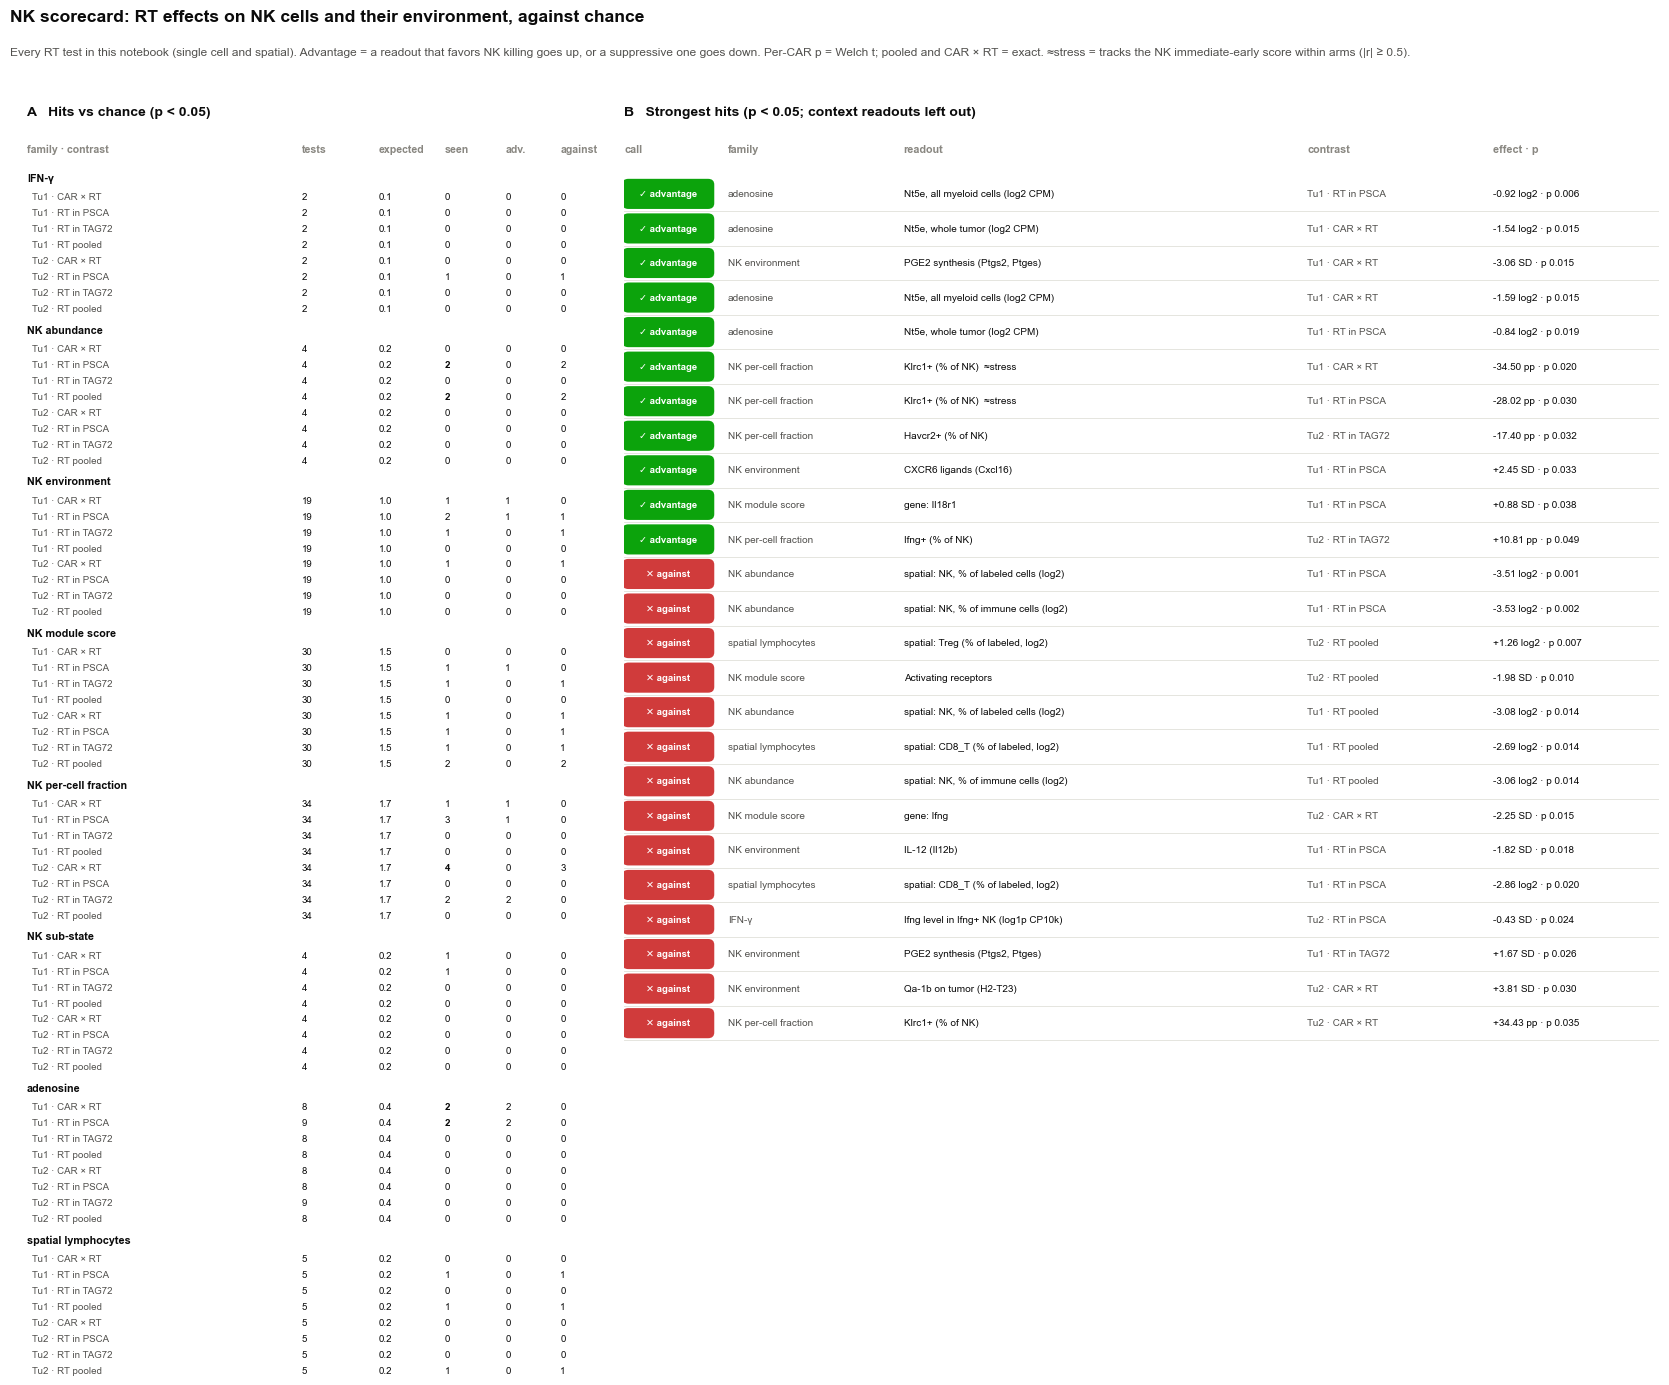

In [15]:
fig = plt.figure(figsize=(17, 11.5))
gs = GridSpec(1, 2, width_ratios=[0.85, 1.6], wspace=0.06, left=0.03, right=0.99, top=0.88, bottom=0.04)
fig.suptitle("NK scorecard: RT effects on NK cells and their environment, against chance", x=0.02, y=0.975, ha="left",
             fontsize=12.6, weight="bold")
fig.text(0.02, 0.935, "Every RT test in this notebook (single cell and spatial). Advantage = a readout that favors NK killing goes up, or a "
         "suppressive one goes down. Per-CAR p = Welch t; pooled and CAR × RT = exact. ≈stress = tracks the NK immediate-early score "
         "within arms (|r| ≥ 0.5).", fontsize=8.6, color=INK2)
ax = fig.add_subplot(gs[0]); ax.axis("off")
ax.text(0.0, 1.0, "A   Hits vs chance (p < 0.05)", transform=ax.transAxes, fontsize=10, va="bottom", weight="bold")
xs = [0.0, 0.5, 0.64, 0.76, 0.87, 0.97]
for x, h in zip(xs, ["family · contrast", "tests", "expected", "seen", "adv.", "against"]):
    ax.text(x, 0.965, h, transform=ax.transAxes, fontsize=7.6, color=MUTED, weight="bold")
y0 = 0.935; CHr = CH.reset_index()
for fam in CHr.family.unique():
    ax.text(0.0, y0, fam, transform=ax.transAxes, fontsize=7.8, weight="bold"); y0 -= 0.019
    for r in CHr[CHr.family == fam].itertuples():
        vals = [r.contrast, f"{r.tests}", f"{r.expected:.1f}", f"{r.p05}", f"{int(getattr(r, 'advantage', 0))}", f"{int(getattr(r, 'against', 0))}"]
        for x, v in zip(xs, vals):
            ax.text(x + (0.01 if x == 0 else 0), y0, v, transform=ax.transAxes, fontsize=7.0, color=INK2 if x == 0 else INK,
                    weight="bold" if (x == xs[3] and r.p05 > 2 * r.expected and r.p05 >= 2) else "normal")
        y0 -= 0.0165
    y0 -= 0.006
ax2 = fig.add_subplot(gs[1]); ax2.axis("off")
ax2.text(0.0, 1.0, "B   Strongest hits (p < 0.05; context readouts left out)", transform=ax2.transAxes, fontsize=10, va="bottom", weight="bold")
cx = [0.0, 0.1, 0.27, 0.66, 0.84]
for x, h in zip(cx, ["call", "family", "readout", "contrast", "effect · p"]):
    ax2.text(x, 0.965, h, transform=ax2.transAxes, fontsize=7.8, color=MUTED, weight="bold")
show_h = pd.concat([HITS[HITS.call == "advantage"].head(16), HITS[HITS.call == "against"].head(14)])
dy = 0.93 / max(len(show_h) + 1, 1)
for i, r in enumerate(show_h.itertuples()):
    y = 0.94 - (i + 0.5) * dy
    fc, ic = (S_GOOD, "✓") if r.call == "advantage" else (S_CRIT, "✕")
    ax2.add_patch(mpl.patches.FancyBboxPatch((0.0, y - dy * 0.38), 0.085, dy * 0.76, boxstyle="round,pad=0.002,rounding_size=0.006",
                                             transform=ax2.transAxes, facecolor=fc, edgecolor="none"))
    ax2.text(0.0425, y, f"{ic} {r.call}", transform=ax2.transAxes, ha="center", va="center", fontsize=6.9, color="white", weight="bold")
    unit = "pp" if "%" in r.readout and "log2" not in r.readout else ("log2" if ("log2" in r.readout or "CPM" in r.readout) else "SD")
    ax2.text(cx[1], y, r.family, transform=ax2.transAxes, va="center", fontsize=7.2, color=INK2)
    ax2.text(cx[2], y, str(r.readout)[:52] + ("  ≈stress" if r.tracks_IEG else ""), transform=ax2.transAxes, va="center", fontsize=7.2)
    ax2.text(cx[3], y, r.contrast, transform=ax2.transAxes, va="center", fontsize=7.2, color=INK2)
    ax2.text(cx[4], y, f"{r.est:+.2f} {unit} · p {fmt_p(r.p_use)}", transform=ax2.transAxes, va="center", fontsize=7.2)
    ax2.plot([0, 1], [y - dy / 2] * 2, transform=ax2.transAxes, color=GRID, lw=0.6)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureN5_scorecard.{ext}", bbox_inches="tight")
plt.show()

## 14. Summary

In [16]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print("\n[1] Ifng+ NK cells pooled per arm x site:"); print(POOLED.round(3).to_string())
print("\n[1] Ifng effects (Tu2 and PSCA at Tu2):")
print(IFNG_EFF[IFNG_EFF.effect.isin(["RT Tu2", "PSCA Tu2", "RT Tu1"])][["readout", "effect", "part", "est", "p", "welch"]].round(3).to_string(index=False))
print("\n[1] Ifng GLMM:"); print(GL[GL.gene == "Ifng"].round(4).to_string(index=False))
print("\n[1] Ifng source shares (mean over tumors):")
print((SRC_IFNG.reindex(columns=["NK", "CD8_T", "NKT", "CD4_T", "Treg"]).join(WTM).groupby(["site", "arm"])[["NK", "CD8_T", "NKT", "CD4_T", "Treg"]].mean() * 100).round(0).to_string())
print(f"[1] whole-tumor Ifng vs mac ISG: rho {rho_raw.correlation:.2f} p {rho_raw.pvalue:.3f}; within {rho_within.correlation:.2f} p {rho_within.pvalue:.3f}")
print("\n[1] spatial Ifng:"); print(SP_IFNG[SP_IFNG.effect.isin(["RT Tu2", "PSCA Tu2"])][["readout", "effect", "part", "est", "p", "welch"]].round(3).to_string(index=False))
print("\n[3] adenosine:"); print(ADO_EFF[ADO_EFF.part.isin(["PSCA", "TAG72", "pooled", "CARxRT"]) & ADO_EFF.effect.str.startswith("RT")]
                              [["readout", "effect", "part", "est", "p", "welch"]].round(3).to_string(index=False))
print(DID.round(3).to_string(index=False))
print(SPADO_EFF[SPADO_EFF.effect.str.startswith("RT")][["readout", "effect", "part", "est", "p", "welch"]].round(3).to_string(index=False))
print("\n[4] recruitment:"); print(REC[REC.effect.str.startswith("RT") & REC.part.isin(["PSCA", "TAG72", "pooled", "CARxRT"])]
                                [["readout", "effect", "part", "est", "p", "welch"]].round(3).to_string(index=False))
print(ASSOC.round(3).to_string(index=False))
print("\n[5] hits vs chance:"); print(CH.to_string())
print(f"\n[files] {OUT}")
print("=" * 100)

SUMMARY — report these back

[1] Ifng+ NK cells pooled per arm x site:
                 n  ifng_pos   frac
arm      site                      
CyPSCA   1     134        52  0.388
         2      45        23  0.511
CyT72    1     133        39  0.293
         2      95        18  0.189
NoTx     1      29         3  0.103
         2      17         1  0.059
RTCyPSCA 1     182        52  0.286
         2     104        39  0.375
RTCyT72  1     190        69  0.363
         2      79        21  0.266

[1] Ifng effects (Tu2 and PSCA at Tu2):
                             readout   effect   part     est     p  welch
                  Ifng+ NK (% of NK)   RT Tu1   PSCA  -6.040 0.800  0.632
                  Ifng+ NK (% of NK)   RT Tu1  TAG72   1.405 0.700  0.934
                  Ifng+ NK (% of NK)   RT Tu1 pooled  -2.318 0.790    NaN
                  Ifng+ NK (% of NK)   RT Tu1 CARxRT  -7.445 0.665    NaN
                  Ifng+ NK (% of NK)   RT Tu2   PSCA -14.454 0.300  0.229
            